In [1]:
#data manipulation
import pandas as pd
import numpy as np

#viz
import seaborn as sns
import matplotlib.pyplot as plt

#NLP
import re
import nltk
import string
from nltk import sent_tokenize, word_tokenize
from nltk.tokenize.toktok import ToktokTokenizer
from bs4 import BeautifulSoup
import spacy
from nltk.stem import WordNetLemmatizer

%matplotlib inline

#MISC
import warnings
warnings.filterwarnings('ignore')
import unicodedata

In [2]:
#Reading  data files
df = pd.read_csv(r"train.csv")
test = pd.read_csv(r"test.csv")
test_labels = pd.read_csv(r"test_labels.csv")

In [3]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [4]:
df.shape

(159571, 8)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
id               159571 non-null object
comment_text     159571 non-null object
toxic            159571 non-null int64
severe_toxic     159571 non-null int64
obscene          159571 non-null int64
threat           159571 non-null int64
insult           159571 non-null int64
identity_hate    159571 non-null int64
dtypes: int64(6), object(2)
memory usage: 9.7+ MB


In [6]:
df.describe()

,toxic,severe_toxic,obscene,threat,insult,identity_hate
count,159571.000000,159571.000000,159571.000000,159571.000000,159571.000000,159571.000000
mean,0.095844,0.009996,0.052948,0.002996,0.049364,0.008805
std,0.294379,0.099477,0.223931,0.054650,0.216627,0.093420
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [7]:
# Let's create another column "bad_comment" denoting any type of toxicity in the comment

df["bad_comment"] = df.iloc[:,2:].sum(axis = 1)
df["bad_comment"][df["bad_comment"] != 0] = 1

In [8]:
df.head(20)

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0
5,00025465d4725e87,"""\n\nCongratulations from me as well, use the ...",0,0,0,0,0,0,0
6,0002bcb3da6cb337,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0,1
7,00031b1e95af7921,Your vandalism to the Matt Shirvington article...,0,0,0,0,0,0,0
8,00037261f536c51d,Sorry if the word 'nonsense' was offensive to ...,0,0,0,0,0,0,0
9,00040093b2687caa,alignment on this subject and which are contra...,0,0,0,0,0,0,0


In [9]:
# Let's see the number of comments in each toxicity type
counts = df.iloc[:,2:].sum()
counts

toxic            15294
severe_toxic      1595
obscene           8449
threat             478
insult            7877
identity_hate     1405
bad_comment      16225
dtype: int64

In [10]:
for i in counts.index:
    print("{:.2f}".format(counts[i]*100/df.shape[0])+ " Percentage of comments are "+ i)

9.58 Percentage of comments are toxic
1.00 Percentage of comments are severe_toxic
5.29 Percentage of comments are obscene
0.30 Percentage of comments are threat
4.94 Percentage of comments are insult
0.88 Percentage of comments are identity_hate
10.17 Percentage of comments are bad_comment


<b> Most bad_comments are also toxic

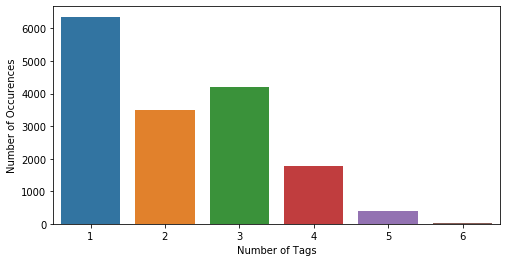

In [11]:
# Let's see the number of comments which have multiple tags

multiple_tags = df.iloc[:,2:8].sum(axis = 1)
tags_count = multiple_tags.value_counts()

plt.figure(figsize = (8,4))

sns.barplot(tags_count.index[1:],tags_count.values[1:])
plt.ylabel("Number of Occurences")
plt.xlabel("Number of Tags")
plt.show()


<b> Of all the bad_comments many of them have 1 to 4 tags and a very few have 5 or 6 tags

In [12]:
matrix = np.zeros((7,7), dtype = int)
matrix = pd.DataFrame(matrix)
matrix.columns = ['toxic', 'severe_toxic', 'obscene', 'threat',
       'insult', 'identity_hate', 'bad_comment']
matrix.index = ['toxic', 'severe_toxic', 'obscene', 'threat',
       'insult', 'identity_hate', 'bad_comment']
for i in range(len(matrix.columns)):
    for j in range(len(matrix.index)):
        if i >= j:
            matrix.loc[matrix.columns[i],matrix.columns[j]] = len(df[(df[matrix.columns[i]] == 1) & (df[matrix.columns[j]] == 1)])
        else:
             matrix.loc[matrix.columns[i],matrix.columns[j]] = len(df[(df[matrix.columns[i]] == 0) & (df[matrix.columns[j]] == 0)])
        
matrix

,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment
toxic,15294,144277,143754,144248,143744,144174,143346
severe_toxic,1595,1595,151044,157610,151470,156884,143346
obscene,7926,1517,8449,150945,149400,150749,143346
threat,449,112,301,478,151523,157786,143346
insult,7344,1371,6155,307,7877,151449,143346
identity_hate,1302,313,1032,98,1160,1405,143346
bad_comment,15294,1595,8449,478,7877,1405,16225


In [13]:
# Let's try to find more relations between the tags
main_col="toxic"
corr_mats=[]
for other_col in df.columns[2:]:
    confusion_matrix = pd.crosstab(df[main_col], df[other_col])
    corr_mats.append(confusion_matrix)
out = pd.concat(corr_mats,axis=1,keys=df.columns[2:])
out


toxic        severe_toxic       obscene        threat       insult  \
toxic       0      1            0     1       0     1       0    1       0   
toxic                                                                        
0      144277      0       144277     0  143754   523  144248   29  143744   
1           0  15294        13699  1595    7368  7926   14845  449    7950   

            identity_hate       bad_comment         
toxic     1             0     1           0      1  
toxic                                               
0       533        144174   103      143346    931  
1      7344         13992  1302           0  15294

In [14]:
y = []
for main_col in df.columns[2:]:
    corr_mats=[]
    for other_col in df.columns[2:]:
        confusion_matrix = pd.crosstab(df[main_col], df[other_col])
        corr_mats.append(confusion_matrix)
        out = pd.concat(corr_mats,axis=1,keys=df.columns[2:])
    y.append(out)
Final_Table = pd.concat(y,axis = 0,keys=df.columns[2:])

In [15]:
Final_Table

toxic        severe_toxic       obscene        threat  \
toxic                     0      1            0     1       0     1       0   
              toxic                                                           
toxic         0      144277      0       144277     0  143754   523  144248   
              1           0  15294        13699  1595    7368  7926   14845   
severe_toxic  0      144277  13699       157976     0  151044  6932  157610   
              1           0   1595            0  1595      78  1517    1483   
obscene       0      143754   7368       151044    78  151122     0  150945   
              1         523   7926         6932  1517       0  8449    8148   
threat        0      144248  14845       157610  1483  150945  8148  159093   
              1          29    449          366   112     177   301       0   
insult        0      143744   7950       151470   224  149400  2294  151523   
              1         533   7344         6506  1371    1722  6155    7570   
identity_hate 0      144174  13992       156884  1282  150749  7417  157786   
              1         103   1302         1092   313     373  1032    1307   
bad_comment   0      143346      0       143346     0  143346     0  143346   
              1         931  15294        14630  1595    7776  8449   15747   

                          insult       identity_hate       bad_comment         
toxic                  1       0     1             0     1           0      1  
              toxic                                                            
toxic         0       29  143744   533        144174   103      143346    931  
              1      449    7950  7344         13992  1302           0  15294  
severe_toxic  0      366  151470  6506        156884  1092      143346  14630  
              1      112     224  1371          1282   313           0   1595  
obscene       0      177  149400  1722        150749   373      143346   7776  
              1      301    2294  6155          7417  1032           0   8449  
threat        0        0  151523  7570        157786  1307      143346  15747  
              1      478     171   307           380    98           0    478  
insult        0      171  151694     0        151449   245      143346   8348  
              1      307       0  7877          6717  1160           0   7877  
identity_hate 0      380  151449  6717        158166     0      143346  14820  
              1       98     245  1160             0  1405           0   1405  
bad_comment   0        0  143346     0        143346     0      143346      0  
              1      478    8348  7877         14820  1405           0  16225

In [16]:
# Cheking if there are any blanks in 'comment_text' column
min(df['comment_text'].apply(len))

6

<b> No blanks in 'comment_text' column as the minimum length is 6

# EDA based on "bad_comment"

## Char count in each comment

In [17]:
df['comment_len'] = [len(x) for x in df['comment_text']]
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment,comment_len
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0,264
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0,112
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0,233
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0,622
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0,67


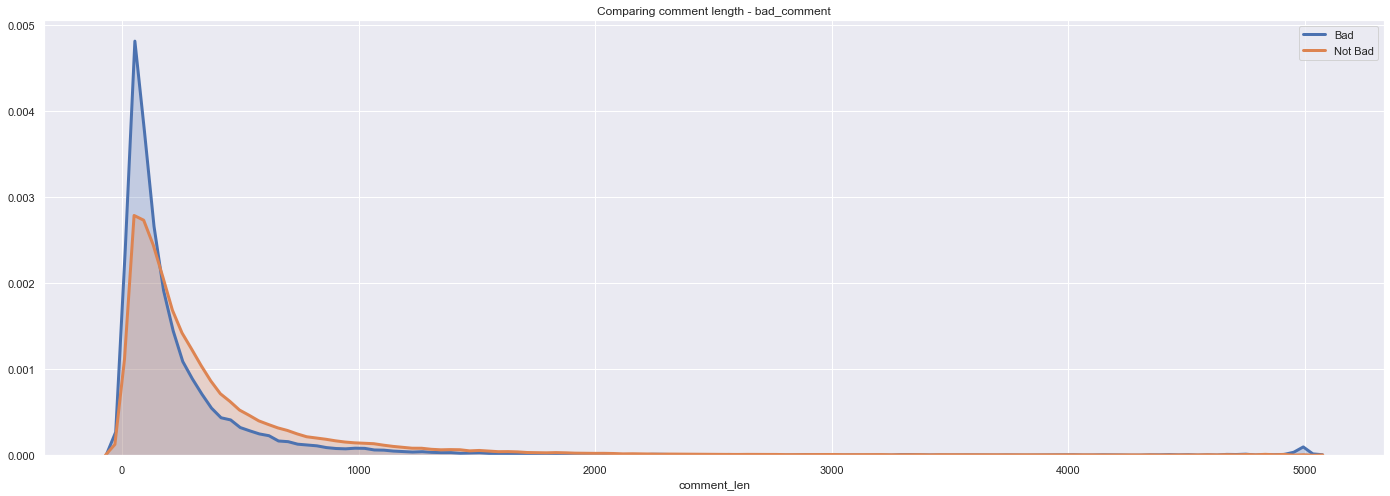

In [18]:
sns.set()

data_1 = df.loc[df['bad_comment'] == 1,'comment_len']
data_2 = df.loc[df['bad_comment'] == 0,'comment_len']
fig = plt.figure(figsize = (24,8))
sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= 'Bad')
sns.distplot(data_2,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= 'Not Bad')
plt.title(f'Comparing comment length - bad_comment')
plt.show()

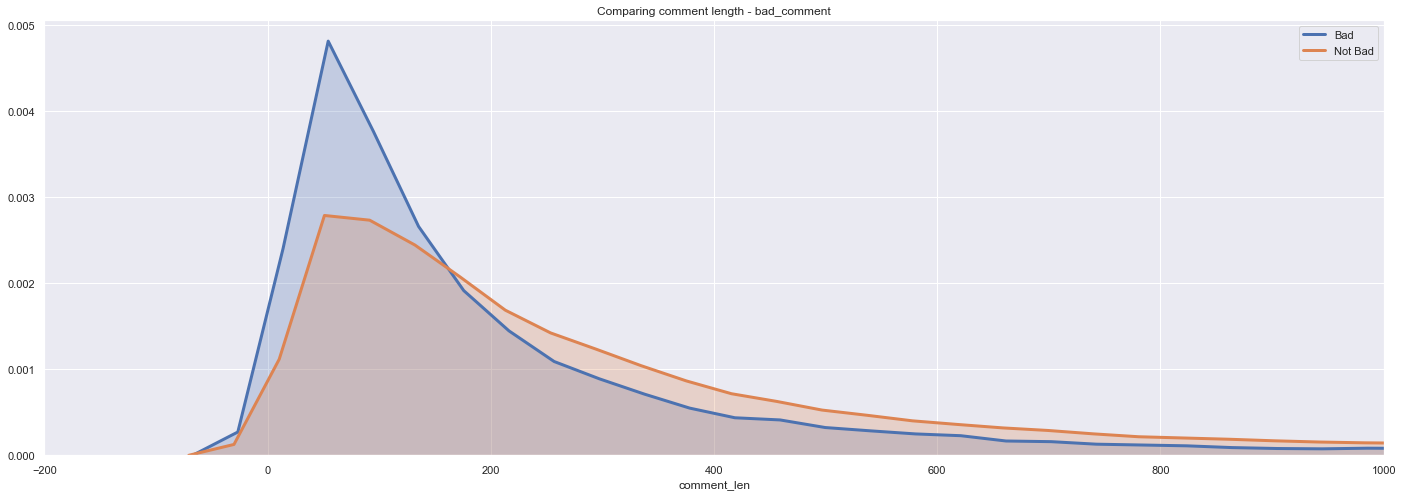

In [19]:
# Zooming in on -200 to 1000
data_1 = df.loc[df['bad_comment'] == 1,'comment_len']
data_2 = df.loc[df['bad_comment'] == 0,'comment_len']
fig = plt.figure(figsize = (24,8))
sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= 'Bad')
sns.distplot(data_2,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= 'Not Bad')
plt.xlim(-200,1000)
plt.title(f'Comparing comment length - bad_comment')
plt.show()

## Word Count in each comment

In [20]:
df['word_count'] = [len(x.split()) for x in df['comment_text']]
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment,comment_len,word_count
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0,264,43
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0,112,17
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0,233,42
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0,622,113
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0,67,13


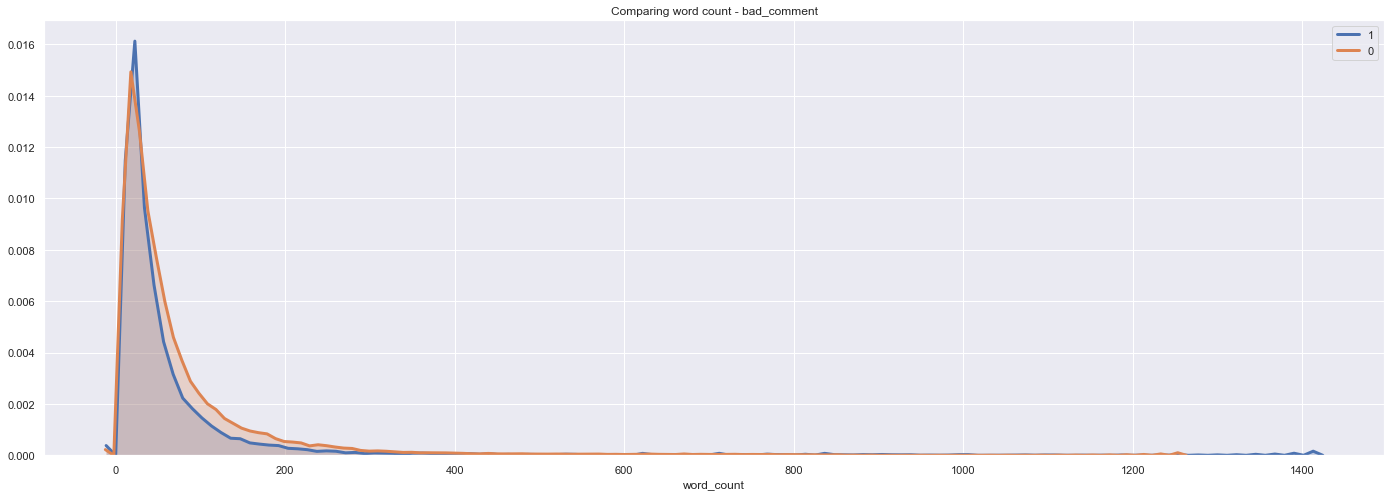

In [21]:
sns.set()

data_1 = df.loc[df['bad_comment'] == 1,'word_count']
data_2 = df.loc[df['bad_comment'] == 0,'word_count']
fig = plt.figure(figsize = (24,8))
sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '1')
sns.distplot(data_2,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '0')
plt.title(f'Comparing word count - bad_comment')
plt.show()

<b> There seems to be no significant difference

## Sentence Count in each comment

In [22]:
df['sentence_count'] = [len(sent_tokenize(x)) for x in df['comment_text']]
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment,comment_len,word_count,sentence_count
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0,264,43,3
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0,112,17,4
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0,233,42,3
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0,622,113,4
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0,67,13,2


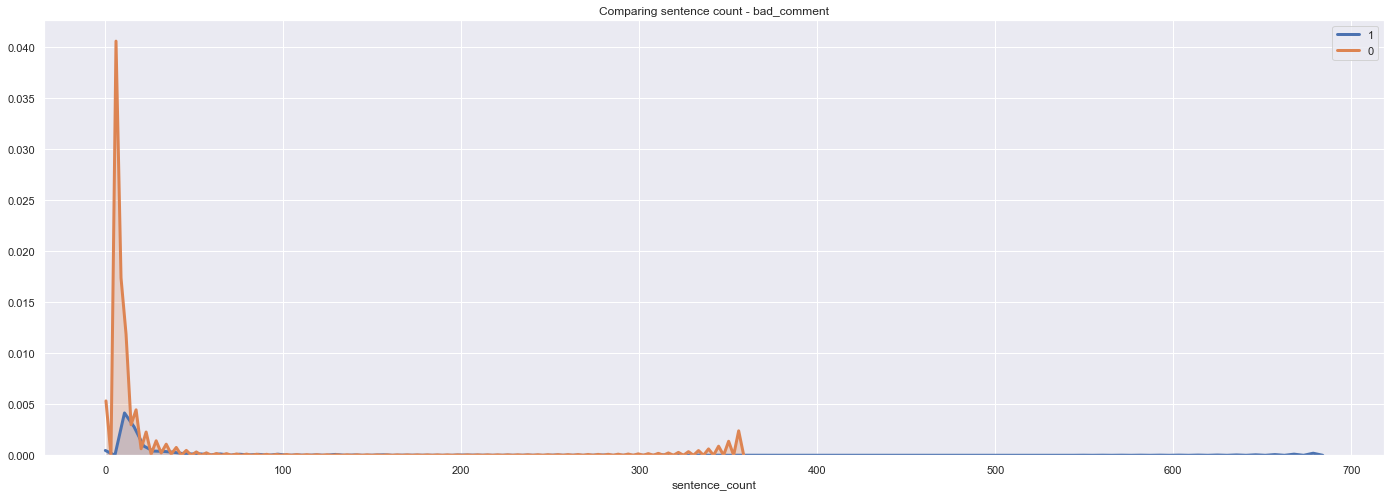

In [23]:
data_1 = df.loc[df['bad_comment'] == 1,'sentence_count']
data_2 = df.loc[df['bad_comment'] == 0,'sentence_count']
fig = plt.figure(figsize = (24,8))
sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '1')
sns.distplot(data_2,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '0')
plt.title(f'Comparing sentence count - bad_comment')
plt.show()

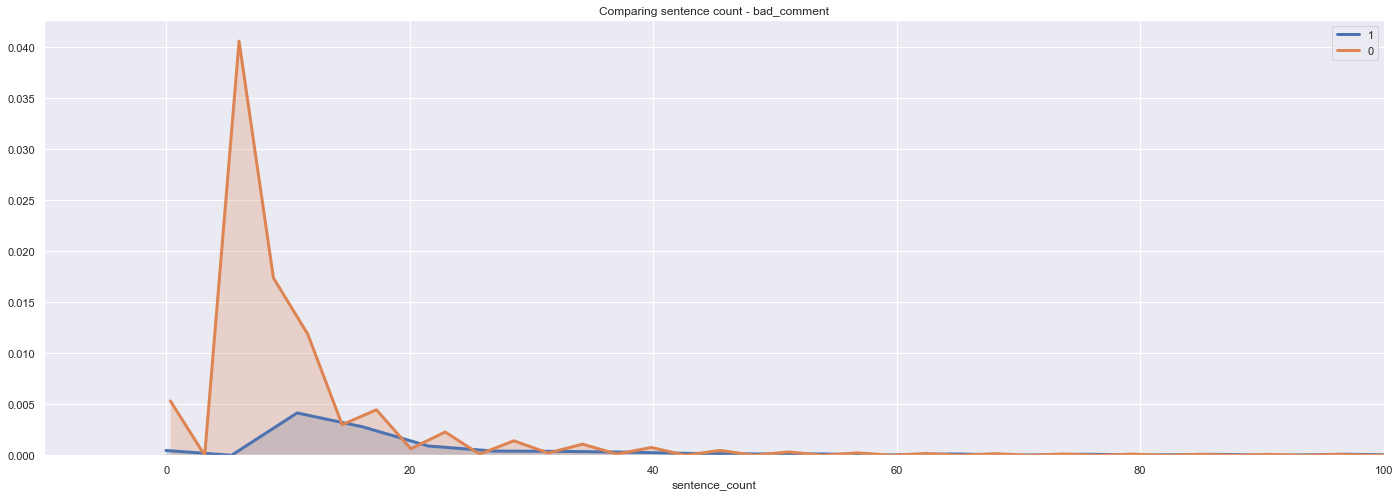

In [24]:
# Zooming in on -10 to 100
data_1 = df.loc[df['bad_comment'] == 1,'sentence_count']
data_2 = df.loc[df['bad_comment'] == 0,'sentence_count']
fig = plt.figure(figsize = (24,8))
sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '1')
sns.distplot(data_2,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '0')
plt.xlim(-10,100)
plt.title(f'Comparing sentence count - bad_comment')
plt.show()

<b> There seems to be significant difference here, could be used as feature in the model

## Capitalization

In [25]:
df['upper_case'] = [sum(char.isupper() for char in comment) for comment in df['comment_text']]
df['upper_case_perc'] = [sum(char.isupper() for char in comment)/len(comment) for comment in df['comment_text']]
df.head(20)

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment,comment_len,word_count,sentence_count,upper_case,upper_case_perc
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0,264,43,3,17,0.064394
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0,112,17,4,8,0.071429
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0,233,42,3,4,0.017167
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0,622,113,4,11,0.017685
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0,67,13,2,2,0.029851
5,00025465d4725e87,"""\n\nCongratulations from me as well, use the ...",0,0,0,0,0,0,0,65,13,2,1,0.015385
6,0002bcb3da6cb337,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0,1,44,8,1,37,0.840909
7,00031b1e95af7921,Your vandalism to the Matt Shirvington article...,0,0,0,0,0,0,0,115,20,2,4,0.034783
8,00037261f536c51d,Sorry if the word 'nonsense' was offensive to ...,0,0,0,0,0,0,0,472,83,6,7,0.014831
9,00040093b2687caa,alignment on this subject and which are contra...,0,0,0,0,0,0,0,70,12,1,2,0.028571


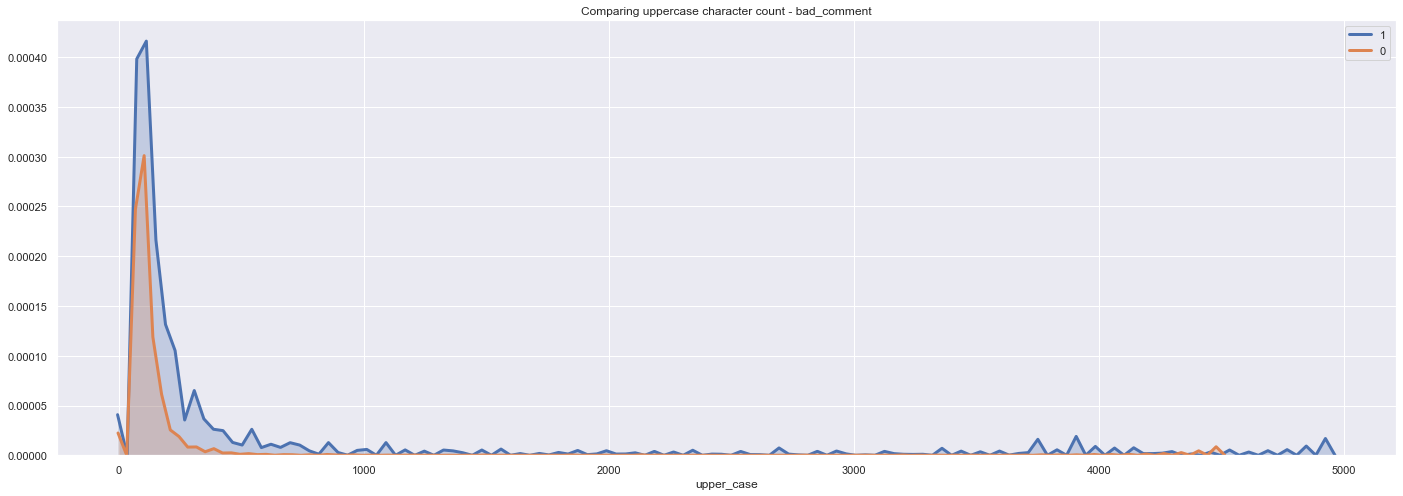

In [26]:
data_1 = df.loc[df['bad_comment'] == 1,'upper_case']
data_2 = df.loc[df['bad_comment'] == 0,'upper_case']
fig = plt.figure(figsize = (24,8))
sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '1')
sns.distplot(data_2,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '0')
plt.title(f'Comparing uppercase character count - bad_comment')
plt.show()

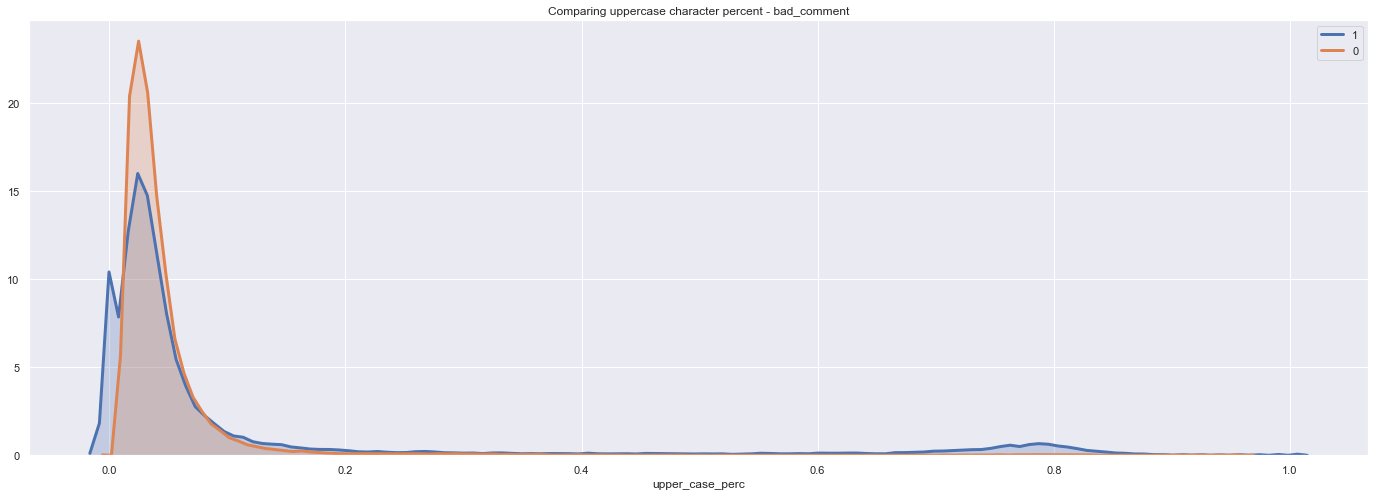

In [27]:
data_1 = df.loc[df['bad_comment'] == 1,'upper_case_perc']
data_2 = df.loc[df['bad_comment'] == 0,'upper_case_perc']
fig = plt.figure(figsize = (24,8))
sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '1')
sns.distplot(data_2,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '0')
plt.title(f'Comparing uppercase character percent - bad_comment')
plt.show()

<b> Comments which have 75 - 85%(approx) upper case letters tend to be toxic

## Punctuations

In [28]:
df['punctuation_count'] = [sum(char in string.punctuation for char in comment) for comment in df['comment_text']] 
df['punctuation_perc'] = [sum(char in string.punctuation for char in comment)/len(comment) for comment in df['comment_text']]
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment,comment_len,word_count,sentence_count,upper_case,upper_case_perc,punctuation_count,punctuation_perc
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0,264,43,3,17,0.064394,10,0.037879
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0,112,17,4,8,0.071429,12,0.107143
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0,233,42,3,4,0.017167,6,0.025751
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0,622,113,4,11,0.017685,21,0.033762
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0,67,13,2,2,0.029851,5,0.074627


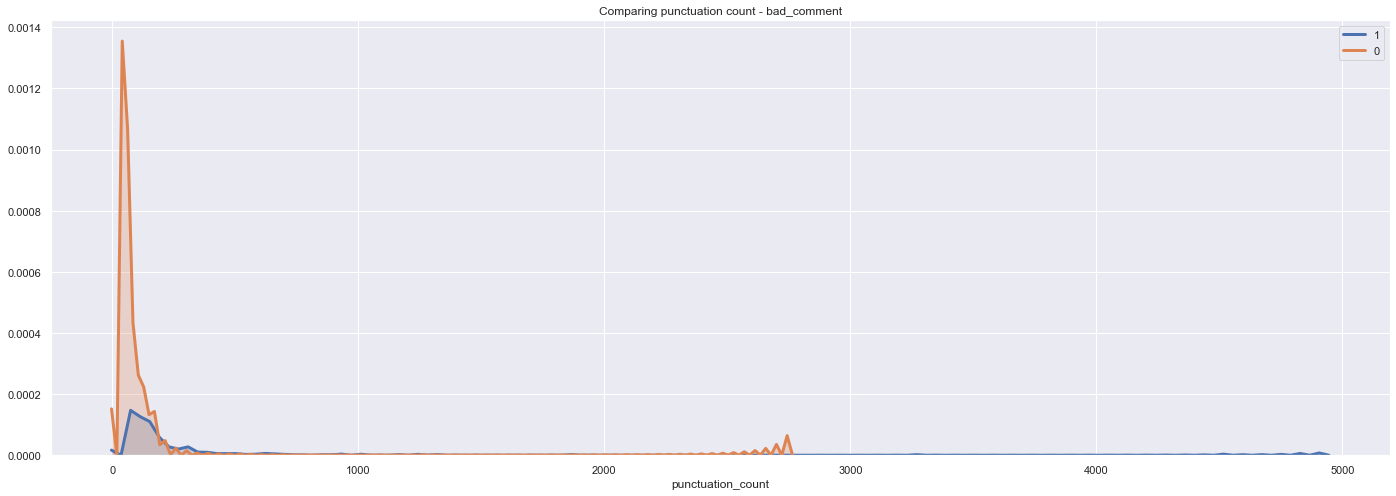

In [29]:
data_1 = df.loc[df['bad_comment'] == 1,'punctuation_count']
data_2 = df.loc[df['bad_comment'] == 0,'punctuation_count']
fig = plt.figure(figsize = (24,8))
sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '1')
sns.distplot(data_2,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '0')
plt.title(f'Comparing punctuation count - bad_comment')
plt.show()

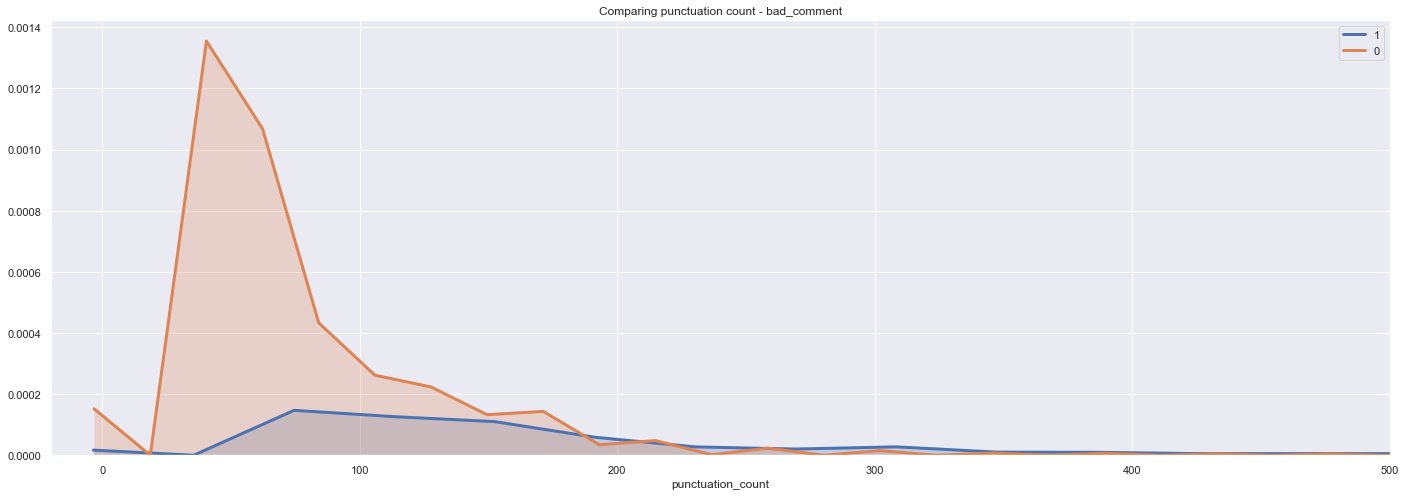

In [30]:
# Zooming in on -10 to 500
data_1 = df.loc[df['bad_comment'] == 1,'punctuation_count']
data_2 = df.loc[df['bad_comment'] == 0,'punctuation_count']
fig = plt.figure(figsize = (24,8))
sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '1')
sns.distplot(data_2,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '0')
plt.xlim(-20,500)
plt.title(f'Comparing punctuation count - bad_comment')
plt.show()

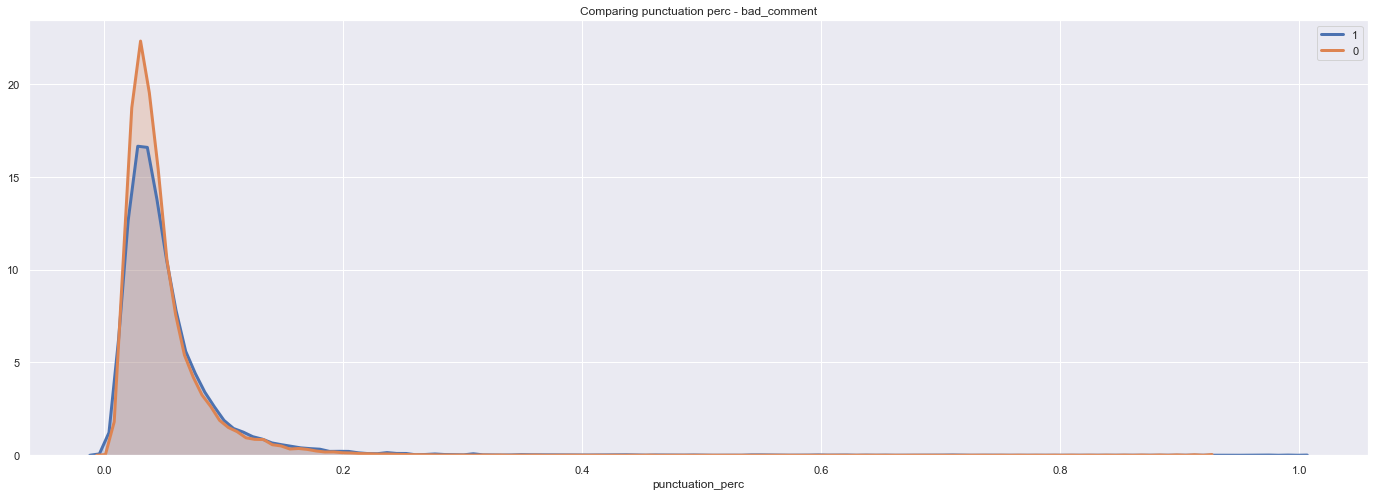

In [31]:
data_1 = df.loc[df['bad_comment'] == 1,'punctuation_perc']
data_2 = df.loc[df['bad_comment'] == 0,'punctuation_perc']
fig = plt.figure(figsize = (24,8))
sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '1')
sns.distplot(data_2,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '0')
plt.title(f'Comparing punctuation perc - bad_comment')
plt.show()

## Most common words in bad and not bad comment

In [32]:
from collections import Counter
from nltk.corpus import stopwords

def getMostCommonWords(comments, n_most_common, stopwords_1=None):

    # flatten comment column into a list of words, and set each to lowercase
    flattened_comments = [word for comment in comments for word in  comment.lower().split()]


    # remove punctuation from comments
    flattened_comments = [''.join(char for char in comment if char not in string.punctuation) for comment in flattened_comments]


    # remove stopwords, if applicable
    if stopwords_1:
        flattened_comments = [word for word in flattened_comments if word not in stopwords_1]

    # remove any empty strings that were created by this process
    flattened_comments = [comment for comment in flattened_comments if comment]

    return Counter(flattened_comments).most_common(n_most_common)

In [33]:
not_bad_comments= df['comment_text'][df['bad_comment'] == 0]
bad_comments= df['comment_text'][df['bad_comment'] == 1]
print(len(not_bad_comments))
print(len(bad_comments))

143346
16225


In [34]:
# Top twenty words in not bad comments with stopwords
getMostCommonWords(not_bad_comments, 20)

[('the', 472191),
 ('to', 279286),
 ('of', 211368),
 ('and', 204898),
 ('a', 192092),
 ('i', 179069),
 ('you', 167174),
 ('is', 162073),
 ('that', 145529),
 ('in', 136696),
 ('it', 121900),
 ('for', 97176),
 ('this', 90989),
 ('not', 87904),
 ('on', 84051),
 ('be', 79288),
 ('as', 73760),
 ('have', 67102),
 ('are', 63076),
 ('if', 55277)]

In [35]:
# Top twenty words in bad comments with stopwords
getMostCommonWords(not_bad_comments, 20)

[('the', 472191),
 ('to', 279286),
 ('of', 211368),
 ('and', 204898),
 ('a', 192092),
 ('i', 179069),
 ('you', 167174),
 ('is', 162073),
 ('that', 145529),
 ('in', 136696),
 ('it', 121900),
 ('for', 97176),
 ('this', 90989),
 ('not', 87904),
 ('on', 84051),
 ('be', 79288),
 ('as', 73760),
 ('have', 67102),
 ('are', 63076),
 ('if', 55277)]

<b> Most of them are stop words we could get better list by removing them

In [36]:
def getMostCommonNonStopWords(comments, n_most_common, stopwords_2=np.array(stopwords.words('english'))):

    # flatten comment column into a list of words, and set each to lowercase
    flattened_comments = [word for comment in comments for word in  comment.lower().split()]
    
        # remove stopwords, if applicable
    if stopwords_2 is not None:
        flattened_comments = [word for word in flattened_comments if word not in stopwords_2]

    # remove punctuation from comments
    flattened_comments = [''.join(char for char in comment if char not in string.punctuation) for comment in flattened_comments]




    # remove any empty strings that were created by this process
    flattened_comments = [comment for comment in flattened_comments if comment]

    return Counter(flattened_comments).most_common(n_most_common)

In [37]:
# Top twenty words in not bad comments with stopwords
getMostCommonNonStopWords(not_bad_comments, 20)

[('article', 53852),
 ('page', 43265),
 ('wikipedia', 32045),
 ('talk', 29514),
 ('please', 28572),
 ('would', 28060),
 ('one', 26393),
 ('like', 23935),
 ('see', 20448),
 ('also', 19717),
 ('think', 18645),
 ('it', 18097),
 ('im', 17046),
 ('articles', 16940),
 ('know', 16638),
 ('edit', 16546),
 ('use', 15809),
 ('people', 15691),
 ('may', 15203),
 ('time', 14210)]

In [38]:
# Top twenty words in bad comments with stopwords
getMostCommonNonStopWords(bad_comments, 20)

[('fuck', 8673),
 ('you', 4318),
 ('like', 3767),
 ('shit', 3653),
 ('wikipedia', 3481),
 ('nigger', 3295),
 ('fucking', 3238),
 ('suck', 3048),
 ('go', 2931),
 ('ass', 2654),
 ('u', 2639),
 ('hate', 2636),
 ('get', 2428),
 ('know', 2347),
 ('page', 2339),
 ('gay', 2249),
 ('im', 2212),
 ('die', 2136),
 ('people', 1983),
 ('fat', 1979)]

<b> Now we can clearly see the difference in the list of top words

## Cleaning the comments

In [39]:
import string
import re
from nltk.tokenize import word_tokenize
TAG_RE = re.compile(r'<[^>]+>') # remove <br> and other html tags

def clean_text(text):
    # lower text
    text = text.lower()

    # Reemove Html Tags like <br>
    text= TAG_RE.sub('', text)

    # remove puncutation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # tokenize_text
    text = [word for word in word_tokenize(text)]

    # remove words that contain numbers
    text = [word for word in text if not any(c.isdigit() for c in word)]
    
    # remove empty tokens
    text = [t for t in text if len(t) > 0]

    # remove words with only one letter
    text = [t for t in text if len(t) > 1]

    # join all
    text = " ".join(text)
    return(text)

In [40]:
df["clean_comments"] = df["comment_text"].apply(lambda x:clean_text(x))
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment,comment_len,word_count,sentence_count,upper_case,upper_case_perc,punctuation_count,punctuation_perc,clean_comments
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0,264,43,3,17,0.064394,10,0.037879,explanation why the edits made under my userna...
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0,112,17,4,8,0.071429,12,0.107143,daww he matches this background colour im seem...
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0,233,42,3,4,0.017167,6,0.025751,hey man im really not trying to edit war its j...
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0,622,113,4,11,0.017685,21,0.033762,more cant make any real suggestions on improve...
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0,67,13,2,2,0.029851,5,0.074627,you sir are my hero any chance you remember wh...


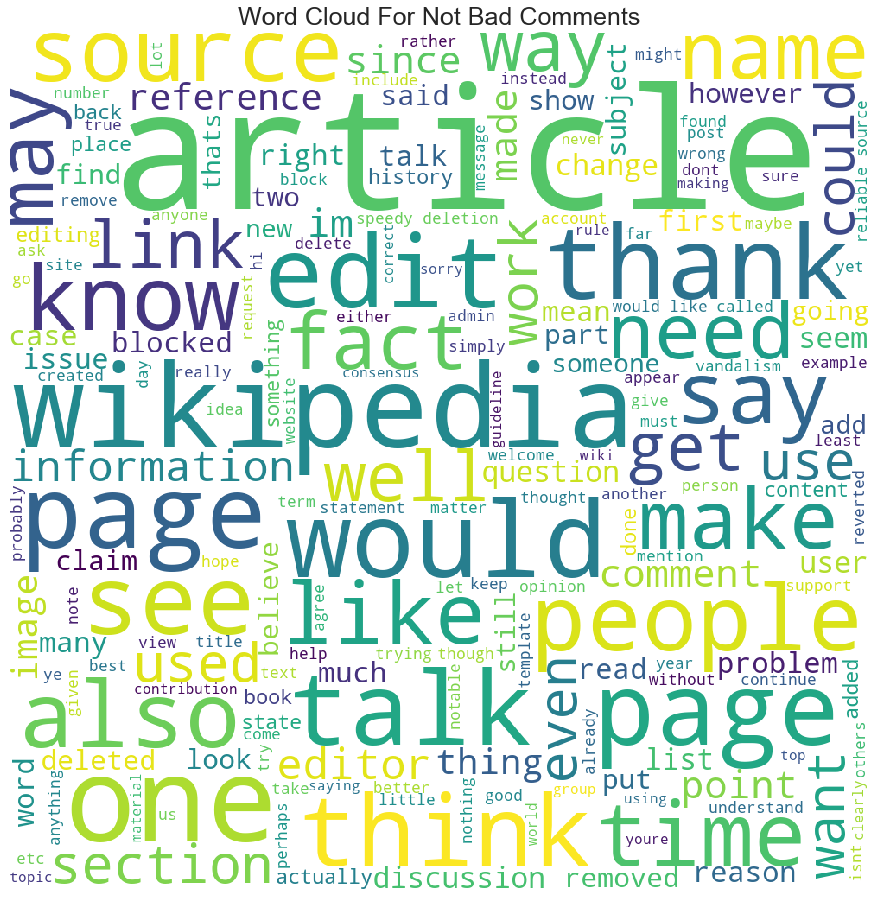

In [41]:
from wordcloud import WordCloud 
   
wordcloud = WordCloud(width = 1000, height = 1000, 
                background_color ='white', 
                min_font_size = 10, stopwords=np.array(stopwords.words('english'))).generate(' '.join(df['clean_comments'][df['bad_comment'] == 0].values)) 
  
# plot the WordCloud image                        
plt.figure(figsize = (19, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.title("Word Cloud For Not Bad Comments", fontdict={'fontsize': 25})
plt.show() 

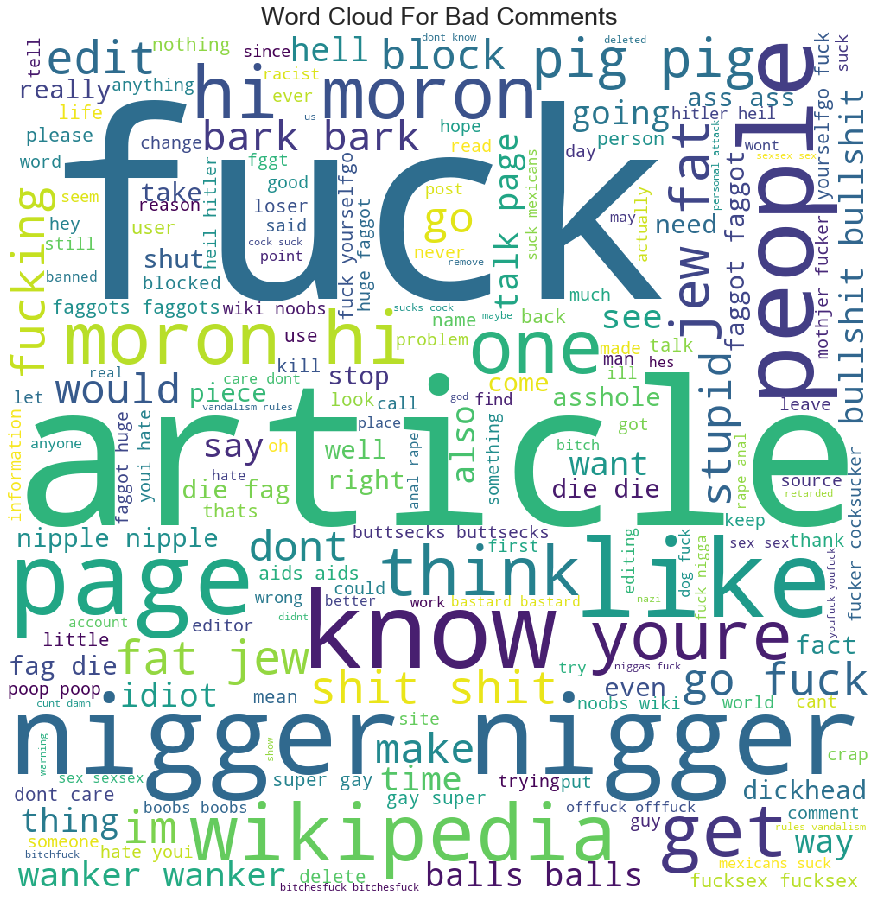

In [42]:
from wordcloud import WordCloud 
   
wordcloud = WordCloud(width = 1000, height = 1000, 
                background_color ='white', 
                min_font_size = 10, stopwords=np.array(stopwords.words('english'))).generate(' '.join(df['clean_comments'][df['bad_comment'] == 1].values)) 
  
# plot the WordCloud image                        
plt.figure(figsize = (19, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.title("Word Cloud For Bad Comments", fontdict={'fontsize': 25})
plt.show() 

# Let's do similar comparison among all 5 tags

In [43]:
df['tag_count'] = df.iloc[:,2:8].sum(axis =1)
df.head(20)

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment,comment_len,word_count,sentence_count,upper_case,upper_case_perc,punctuation_count,punctuation_perc,clean_comments,tag_count
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0,264,43,3,17,0.064394,10,0.037879,explanation why the edits made under my userna...,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0,112,17,4,8,0.071429,12,0.107143,daww he matches this background colour im seem...,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0,233,42,3,4,0.017167,6,0.025751,hey man im really not trying to edit war its j...,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0,622,113,4,11,0.017685,21,0.033762,more cant make any real suggestions on improve...,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0,67,13,2,2,0.029851,5,0.074627,you sir are my hero any chance you remember wh...,0
5,00025465d4725e87,"""\n\nCongratulations from me as well, use the ...",0,0,0,0,0,0,0,65,13,2,1,0.015385,4,0.061538,congratulations from me as well use the tools ...,0
6,0002bcb3da6cb337,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0,1,44,8,1,37,0.840909,0,0.000000,cocksucker before you piss around on my work,4
7,00031b1e95af7921,Your vandalism to the Matt Shirvington article...,0,0,0,0,0,0,0,115,20,2,4,0.034783,4,0.034783,your vandalism to the matt shirvington article...,0
8,00037261f536c51d,Sorry if the word 'nonsense' was offensive to ...,0,0,0,0,0,0,0,472,83,6,7,0.014831,19,0.040254,sorry if the word nonsense was offensive to yo...,0
9,00040093b2687caa,alignment on this subject and which are contra...,0,0,0,0,0,0,0,70,12,1,2,0.028571,0,0.000000,alignment on this subject and which are contra...,0


## Comment Length

toxic row count 15294
severe_toxic row count 1595
obscene row count 8449
threat row count 478
insult row count 7877
identity_hate row count 1405


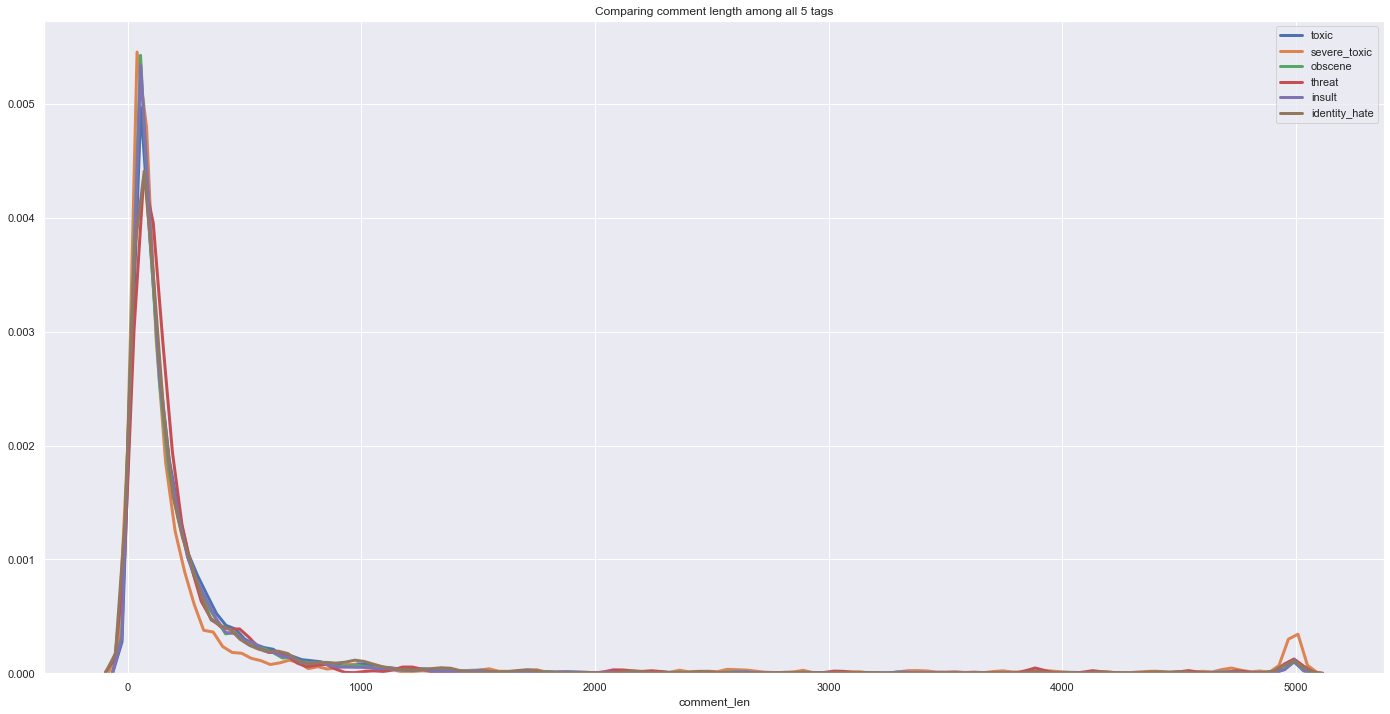

In [44]:
# Plotting comment length for all the comments with these tags

sns.set()
fig = plt.figure(figsize = (24,12))
for column in df.columns[2:8]:
    data_1 = df.loc[df[column] == 1,'comment_len']
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': False, 'linewidth': 3}, 
                 label= column)
    print(f'{column} row count {len(data_1)}')
plt.title(f'Comparing comment length among all 5 tags')
plt.show()

toxic row count 5666
severe_toxic row count 41
obscene row count 317
threat row count 22
insult row count 301
identity_hate row count 54


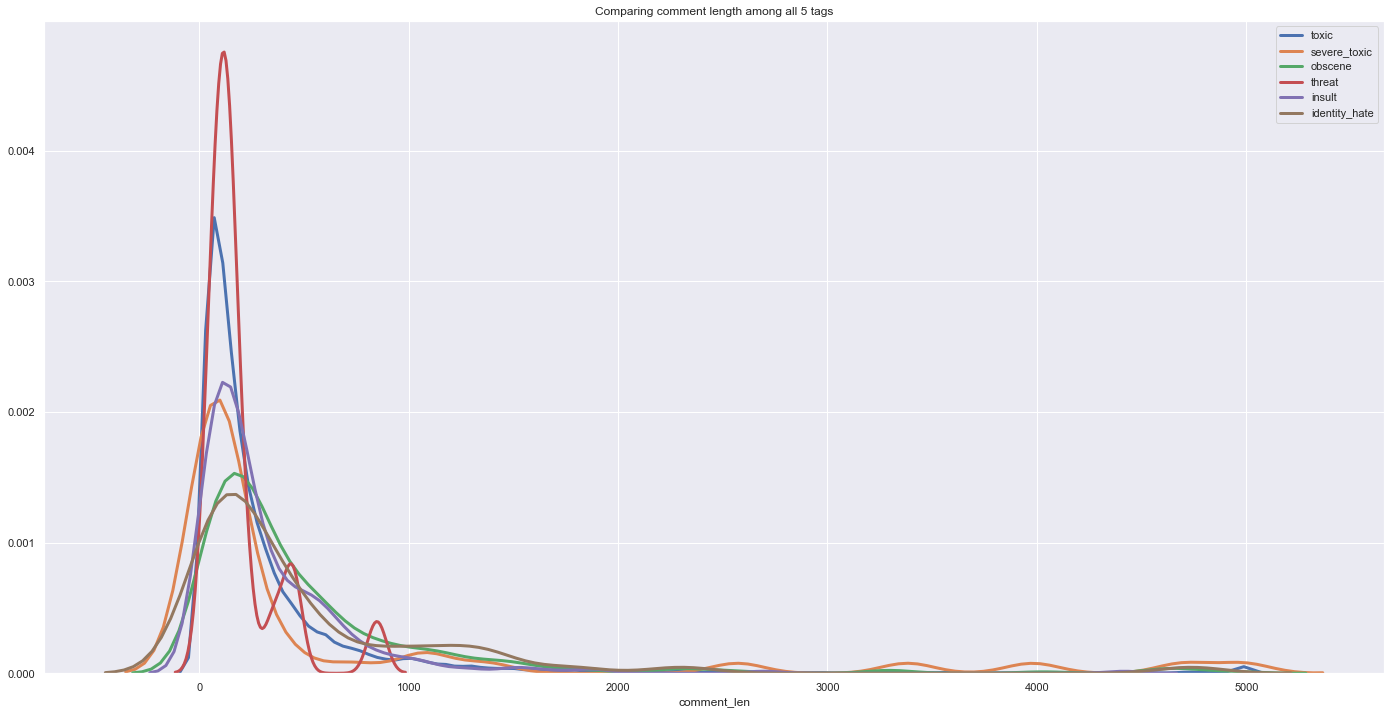

In [45]:
# Plotting comment length for all the comments with only one tag
sns.set()
fig = plt.figure(figsize = (24,12))
for column in df.columns[2:8]:
    if column != 'severe_toxic':
        data_1 = df.loc[(df[column] == 1) & (df['tag_count'] == 1),'comment_len']
    else:
        data_1 = df.loc[(df[column] == 1) & (df['tag_count'] == 2),'comment_len']
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': False, 'linewidth': 3}, 
                 label= column)
    print(f'{column} row count {len(data_1)}')
plt.title(f'Comparing comment length among all 5 tags')
plt.show()

toxic row count 5666
severe_toxic row count 41
obscene row count 1944
threat row count 118
insult row count 1427
identity_hate row count 167


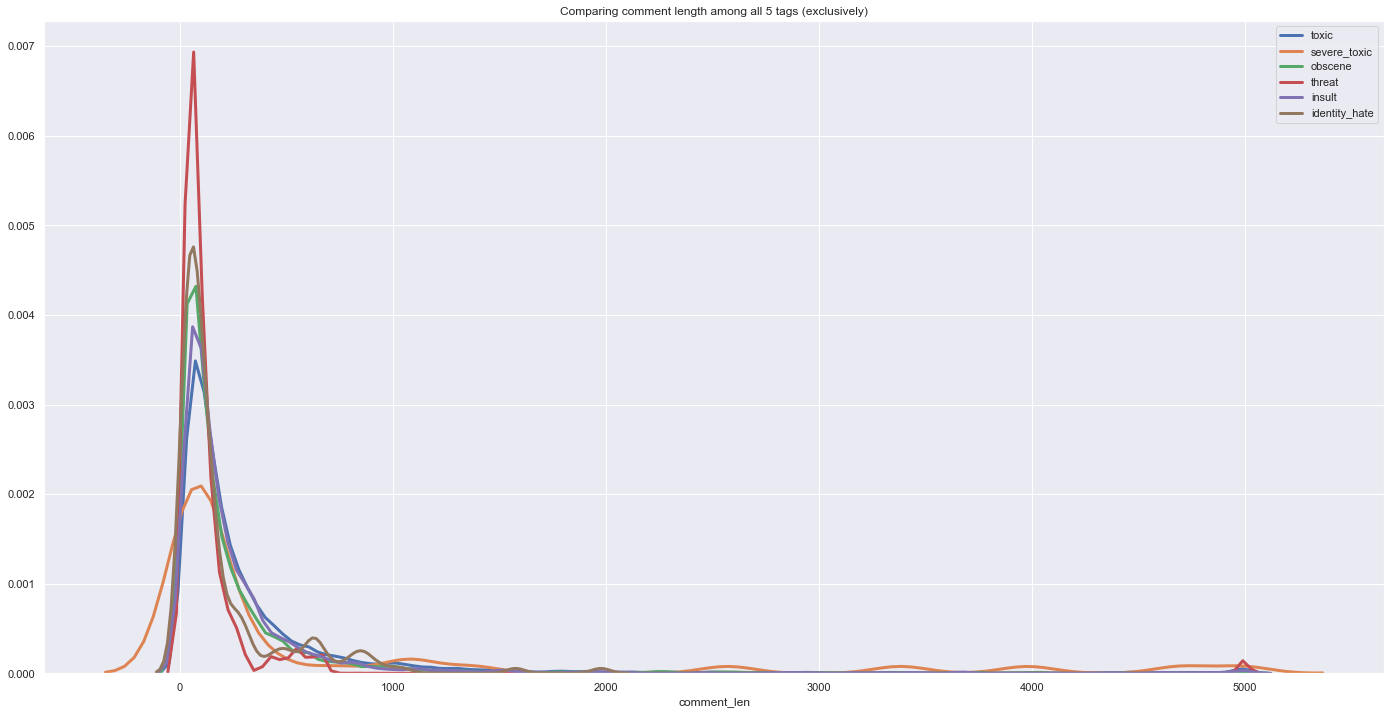

In [46]:
# Plotting comment length for all the comments with any one of five tags and  toxic tag
sns.set()
fig = plt.figure(figsize = (24,12))
for column in df.columns[2:8]:
    if column == 'toxic':
        data_1 = df.loc[(df[column] == 1) & (df['tag_count'] == 1),'comment_len']
    else:
        data_1 = df.loc[(df[column] == 1) & (df['tag_count'] == 2),'comment_len']
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': False, 'linewidth': 3}, 
                 label= column)
    print(f'{column} row count {len(data_1)}')
plt.title(f'Comparing comment length among all 5 tags (exclusively)')
plt.show()

## Word Count

toxic row count 15294
severe_toxic row count 1595
obscene row count 8449
threat row count 478
insult row count 7877
identity_hate row count 1405


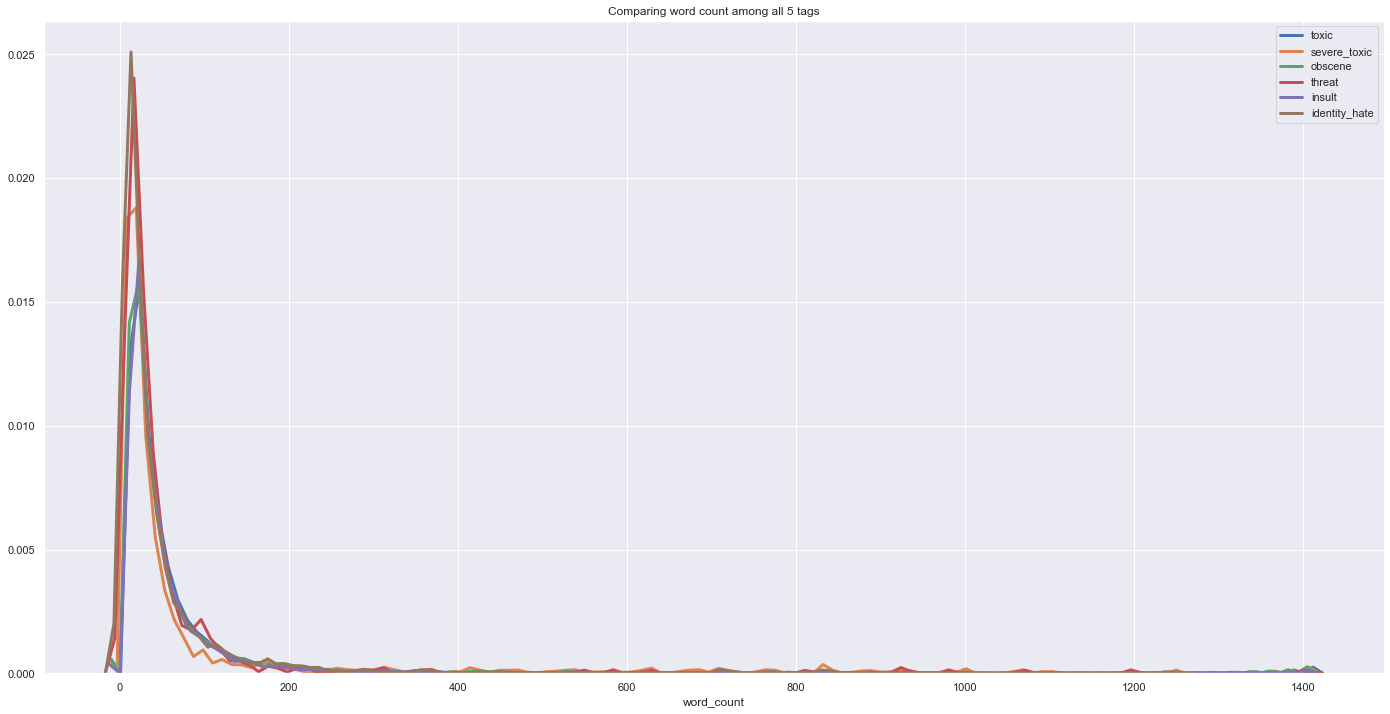

In [47]:
# Plotting word count for all the comments with these tags

sns.set()
fig = plt.figure(figsize = (24,12))
for column in df.columns[2:8]:
    data_1 = df.loc[df[column] == 1,'word_count']
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': False, 'linewidth': 3}, 
                 label= column)
    print(f'{column} row count {len(data_1)}')
plt.title(f'Comparing word count among all 5 tags')
plt.show()

toxic row count 5666
severe_toxic row count 41
obscene row count 1944
threat row count 118
insult row count 1427
identity_hate row count 167


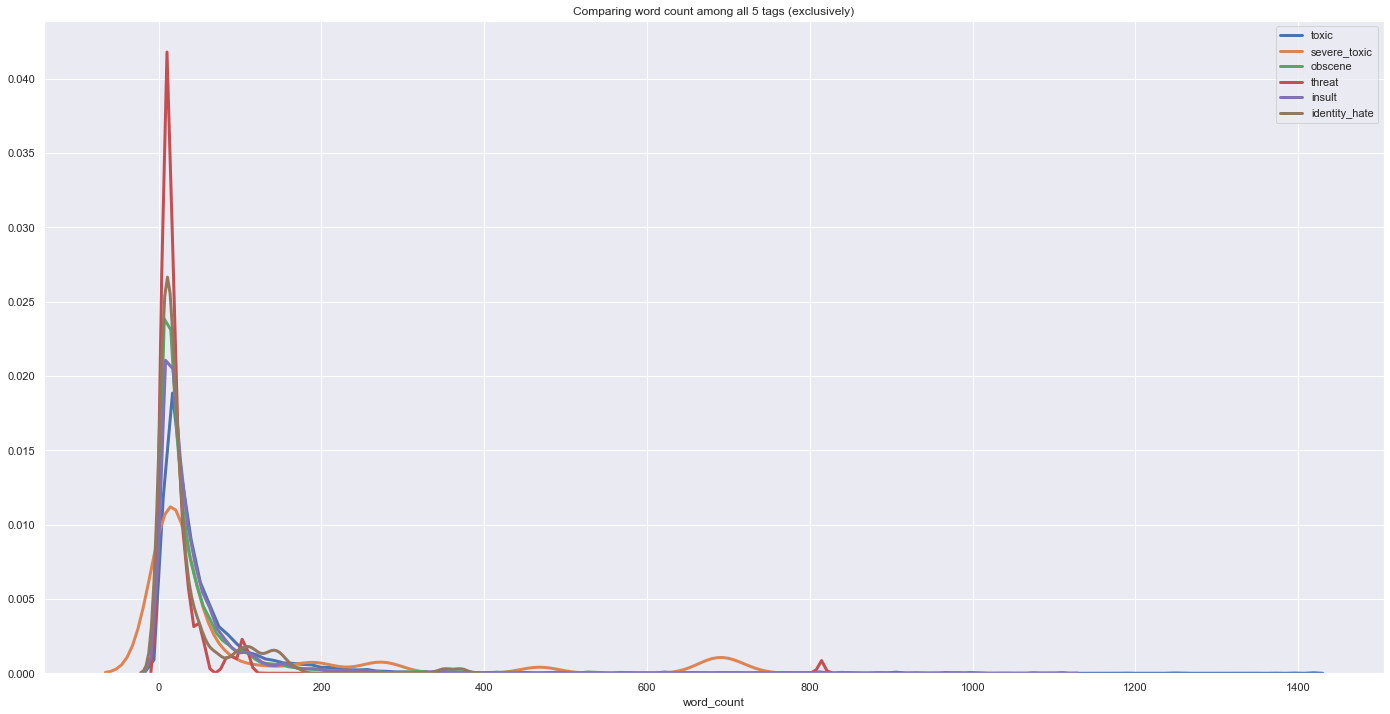

In [48]:
# Plotting word count for all the comments with any one of five tags and  toxic tag
sns.set()
fig = plt.figure(figsize = (24,12))
for column in df.columns[2:8]:
    if column == 'toxic':
        data_1 = df.loc[(df[column] == 1) & (df['tag_count'] == 1),'word_count']
    else:
        data_1 = df.loc[(df[column] == 1) & (df['tag_count'] == 2),'word_count']
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': False, 'linewidth': 3}, 
                 label= column)
    print(f'{column} row count {len(data_1)}')
plt.title(f'Comparing word count among all 5 tags (exclusively)')
plt.show()

## Sentence Count

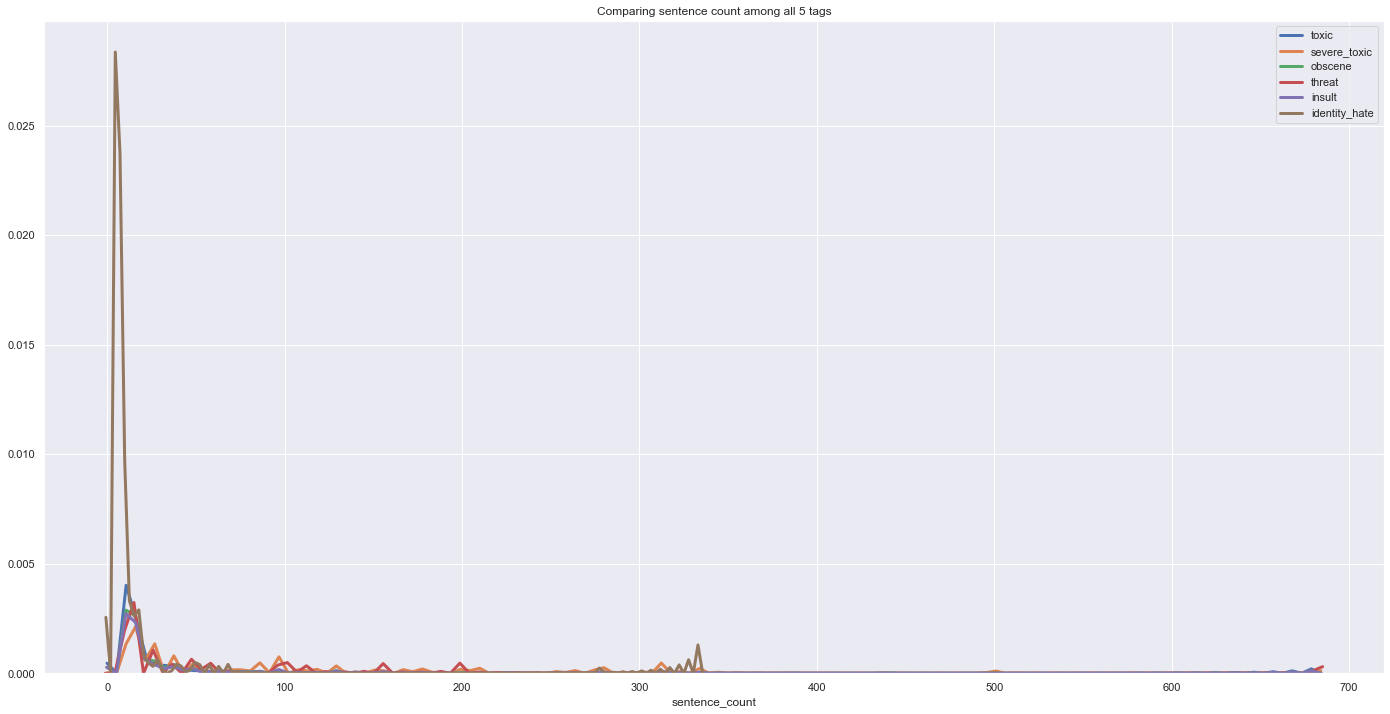

In [49]:
# Plotting sentence count for all the comments with these tags

sns.set()
fig = plt.figure(figsize = (24,12))
for column in df.columns[2:8]:
    data_1 = df.loc[df[column] == 1,'sentence_count']
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': False, 'linewidth': 3}, 
                 label= column)
plt.title(f'Comparing sentence count among all 5 tags')
plt.show()

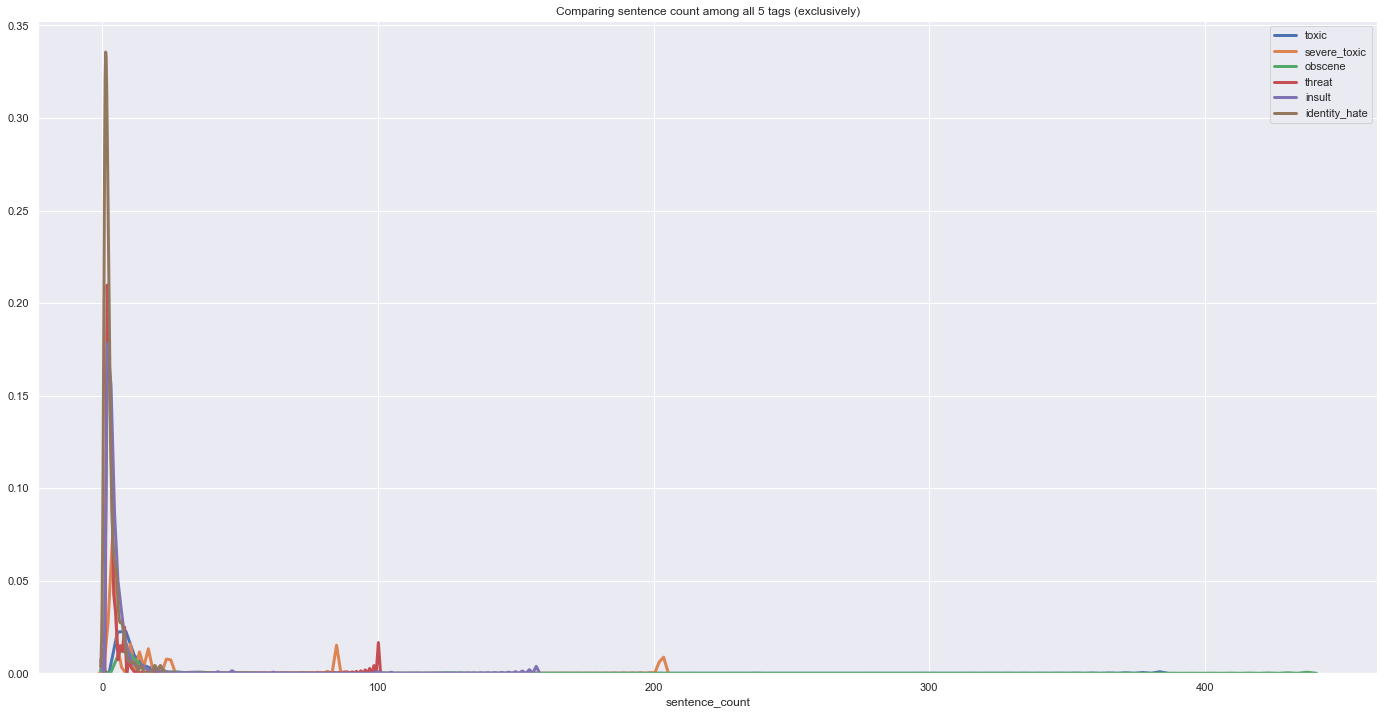

In [50]:
# Plotting word count for all the comments with any one of five tags and  toxic tag
sns.set()
fig = plt.figure(figsize = (24,12))
for column in df.columns[2:8]:
    if column == 'toxic':
        data_1 = df.loc[(df[column] == 1) & (df['tag_count'] == 1),'sentence_count']
    else:
        data_1 = df.loc[(df[column] == 1) & (df['tag_count'] == 2),'sentence_count']
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': False, 'linewidth': 3}, 
                 label= column)
plt.title(f'Comparing sentence count among all 5 tags (exclusively)')
plt.show()

## Capitalization

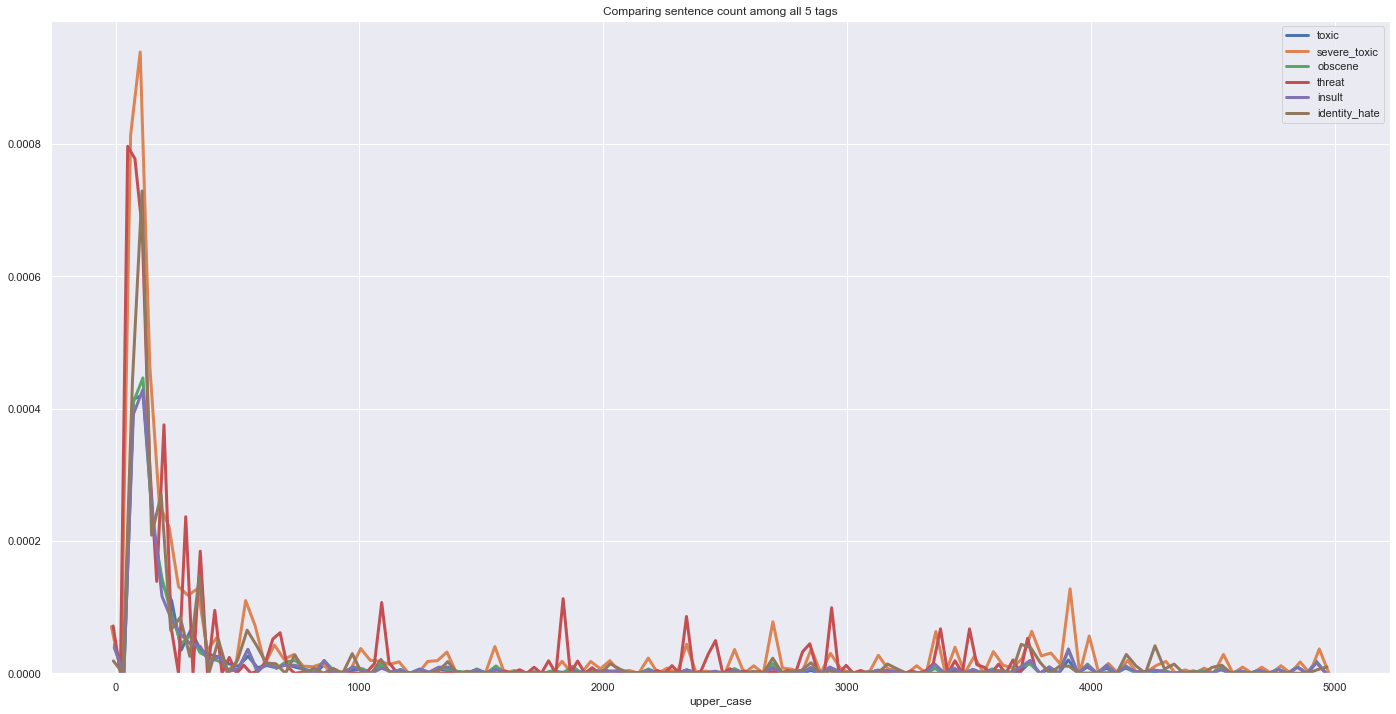

In [51]:
# Plotting capital char count for all the comments with these tags

sns.set()
fig = plt.figure(figsize = (24,12))
for column in df.columns[2:8]:
    data_1 = df.loc[df[column] == 1,'upper_case']
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': False, 'linewidth': 3}, 
                 label= column)
plt.title(f'Comparing sentence count among all 5 tags')
plt.show()

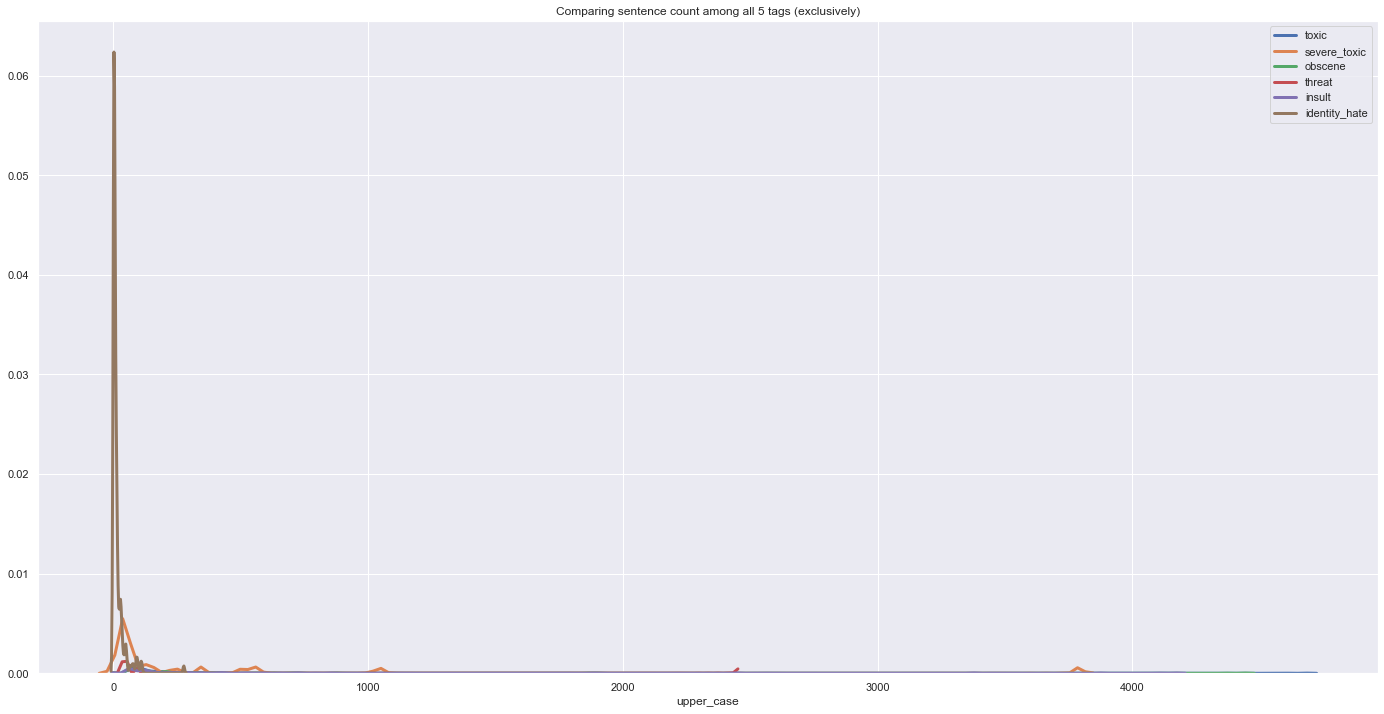

In [52]:
# Plotting capital char count for all the comments with any one of five tags and  toxic tag
sns.set()
fig = plt.figure(figsize = (24,12))
for column in df.columns[2:8]:
    if column == 'toxic':
        data_1 = df.loc[(df[column] == 1) & (df['tag_count'] == 1),'upper_case']
    else:
        data_1 = df.loc[(df[column] == 1) & (df['tag_count'] == 2),'upper_case']
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': False, 'linewidth': 3}, 
                 label= column)
plt.title(f'Comparing sentence count among all 5 tags (exclusively)')
plt.show()

In [53]:
df.columns


Index(['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat',
       'insult', 'identity_hate', 'bad_comment', 'comment_len', 'word_count',
       'sentence_count', 'upper_case', 'upper_case_perc', 'punctuation_count',
       'punctuation_perc', 'clean_comments', 'tag_count'],
      dtype='object')

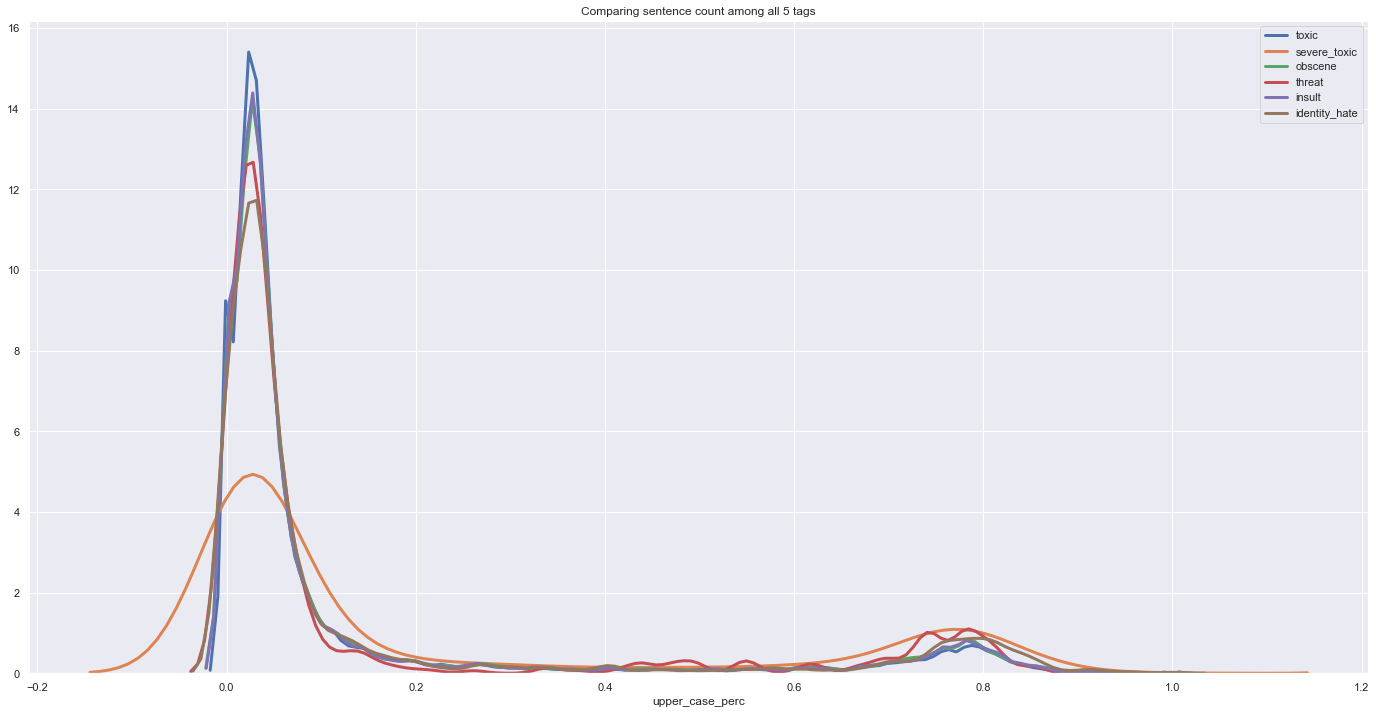

In [54]:
# Plotting capital char percent for all the comments with these tags

sns.set()
fig = plt.figure(figsize = (24,12))
for column in df.columns[2:8]:
    data_1 = df.loc[df[column] == 1,'upper_case_perc']
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': False, 'linewidth': 3}, 
                 label= column)
plt.title(f'Comparing sentence count among all 5 tags')
plt.show()

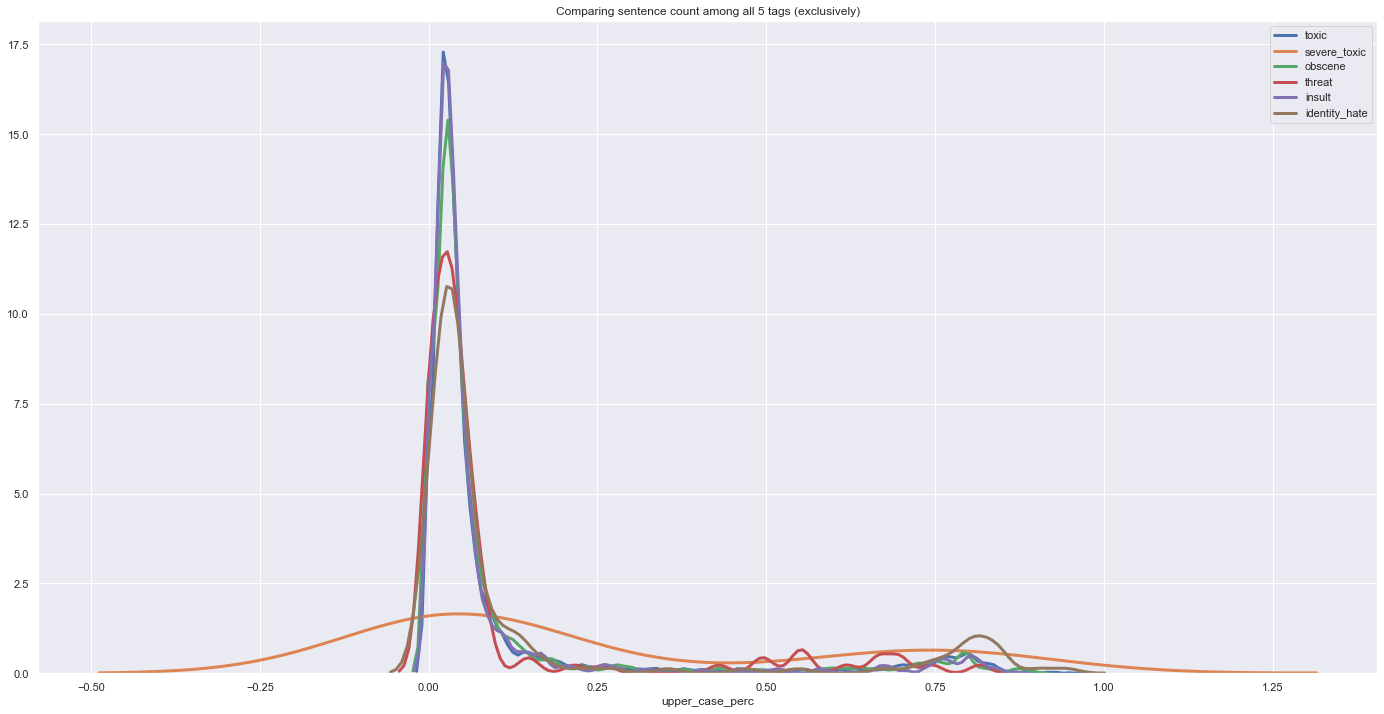

In [55]:
# Plotting capital char percent for all the comments with any one of five tags and  toxic tag
sns.set()
fig = plt.figure(figsize = (24,12))
for column in df.columns[2:8]:
    if column == 'toxic':
        data_1 = df.loc[(df[column] == 1) & (df['tag_count'] == 1),'upper_case_perc']
    else:
        data_1 = df.loc[(df[column] == 1) & (df['tag_count'] == 2),'upper_case_perc']
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': False, 'linewidth': 3}, 
                 label= column)
plt.title(f'Comparing sentence count among all 5 tags (exclusively)')
plt.show()

## Punctuations

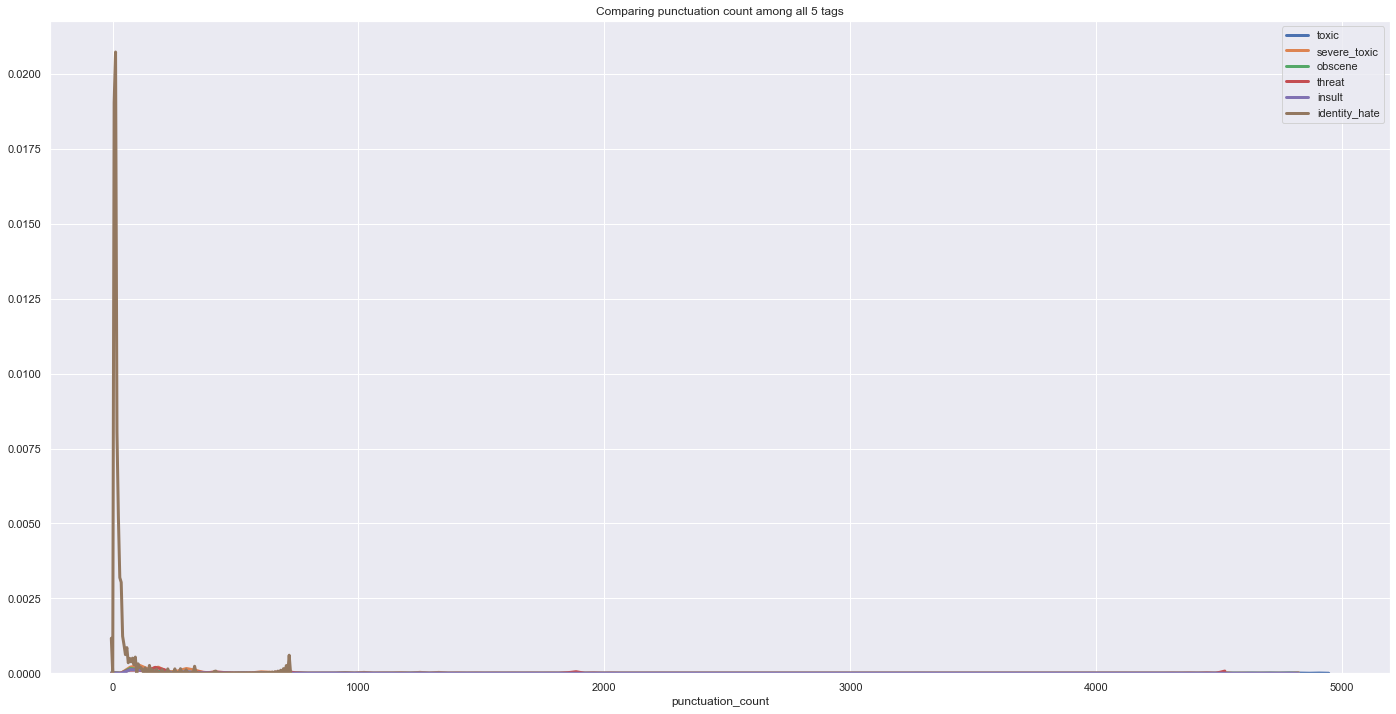

In [56]:
# Plotting punctuation count for all the comments with these tags

sns.set()
fig = plt.figure(figsize = (24,12))
for column in df.columns[2:8]:
    data_1 = df.loc[df[column] == 1,'punctuation_count']
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': False, 'linewidth': 3}, 
                 label= column)
plt.title(f'Comparing punctuation count among all 5 tags')
plt.show()

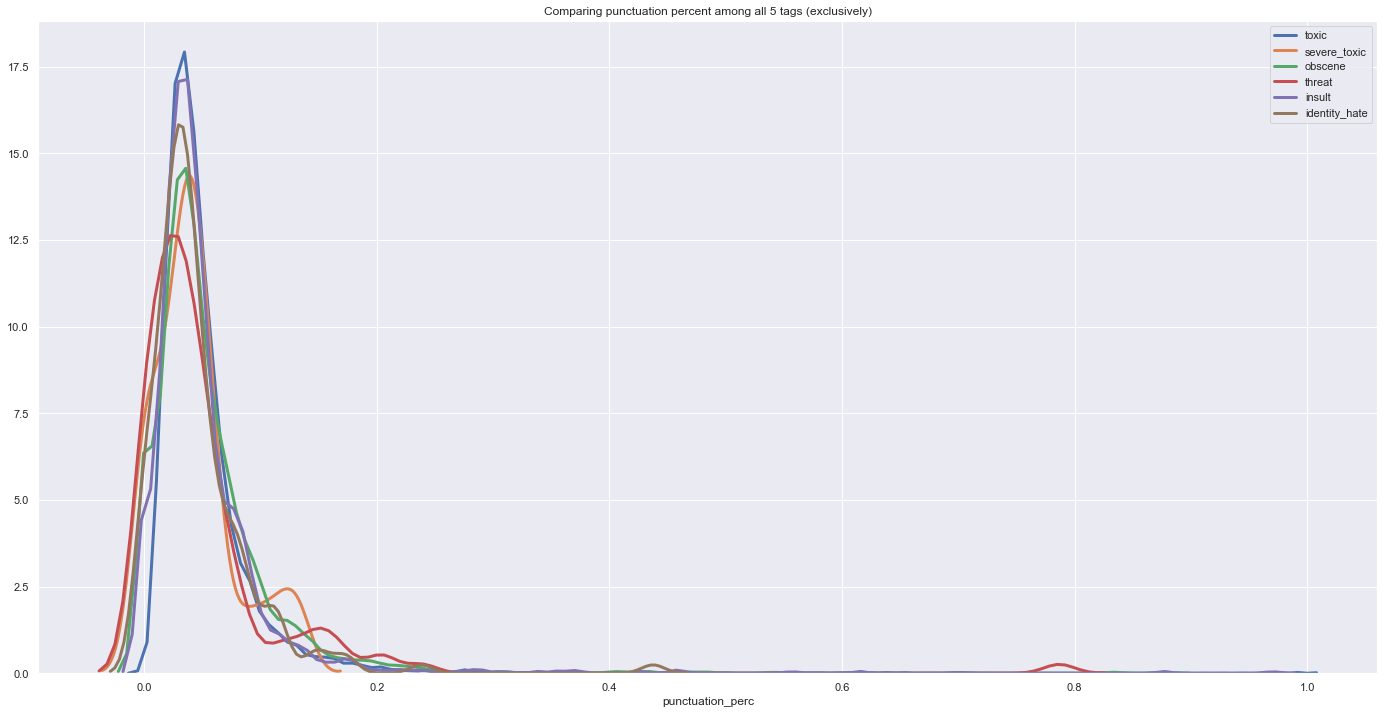

In [57]:
# Plotting capital char percent for all the comments with any one of five tags and  toxic tag
sns.set()
fig = plt.figure(figsize = (24,12))
for column in df.columns[2:8]:
    if column == 'toxic':
        data_1 = df.loc[(df[column] == 1) & (df['tag_count'] == 1),'punctuation_perc']
    else:
        data_1 = df.loc[(df[column] == 1) & (df['tag_count'] == 2),'punctuation_perc']
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': False, 'linewidth': 3}, 
                 label= column)
plt.title(f'Comparing punctuation percent among all 5 tags (exclusively)')
plt.show()

# Let's check most common words for each tag

In [58]:
toxic_comments= df['comment_text'][df['toxic'] == 1]
severe_toxic_comments= df['comment_text'][df['severe_toxic'] == 1]
obscene_comments= df['comment_text'][df['obscene'] == 1]
threat_comments= df['comment_text'][df['threat'] == 1]
insult_comments= df['comment_text'][df['insult'] == 1]
identity_hate_comments= df['comment_text'][df['identity_hate'] == 1]

print(len(toxic_comments))
print(len(severe_toxic_comments))
print(len(obscene_comments))
print(len(threat_comments))
print(len(insult_comments))
print(len(identity_hate_comments))

15294
1595
8449
478
7877
1405


In [59]:
getMostCommonNonStopWords(toxic_comments, 20)

[('fuck', 8613),
 ('you', 4177),
 ('shit', 3583),
 ('like', 3476),
 ('nigger', 3289),
 ('wikipedia', 3260),
 ('fucking', 3191),
 ('suck', 3034),
 ('go', 2833),
 ('hate', 2614),
 ('ass', 2596),
 ('u', 2583),
 ('get', 2283),
 ('gay', 2222),
 ('know', 2181),
 ('page', 2112),
 ('die', 2077),
 ('im', 2035),
 ('fat', 1967),
 ('faggot', 1954)]

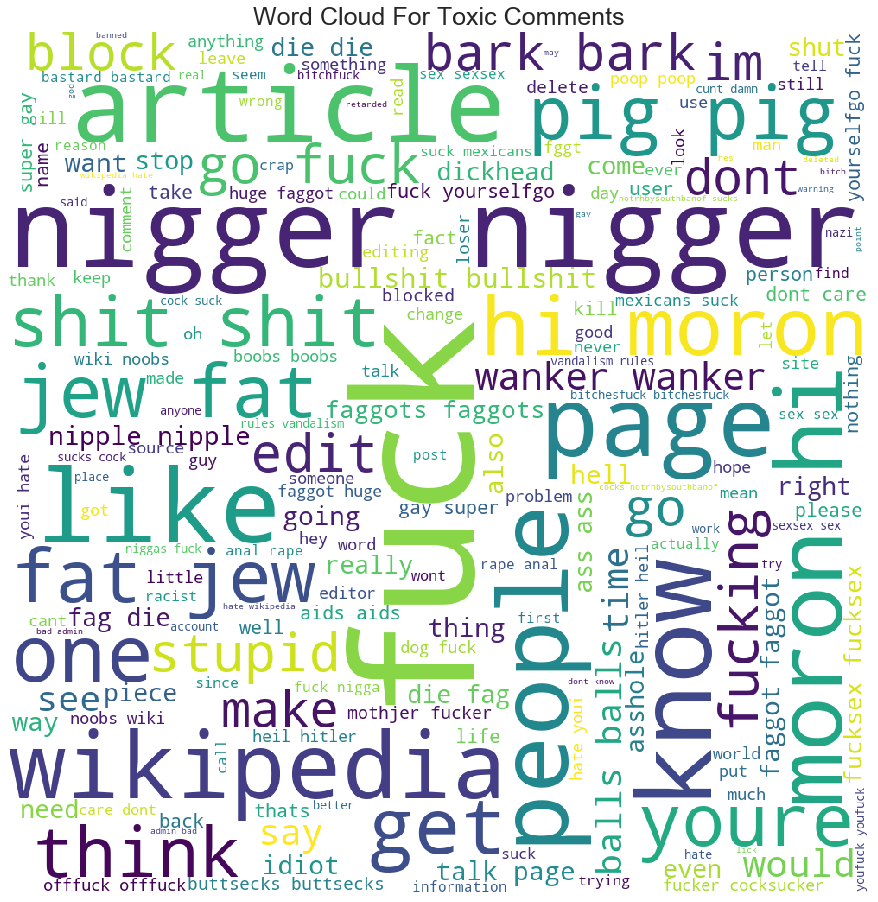

In [60]:
from wordcloud import WordCloud 
   
wordcloud = WordCloud(width = 1000, height = 1000, 
                background_color ='white', 
                min_font_size = 10, stopwords=np.array(stopwords.words('english'))).generate(' '.join(df['clean_comments'][df['toxic']==1].values)) 
  
# plot the WordCloud image                        
plt.figure(figsize = (19, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.title("Word Cloud For Toxic Comments", fontdict={'fontsize': 25})
plt.show() 

In [61]:
getMostCommonNonStopWords(severe_toxic_comments, 20)

[('fuck', 6046),
 ('suck', 2341),
 ('shit', 1877),
 ('ass', 1827),
 ('you', 1720),
 ('faggot', 1570),
 ('u', 1400),
 ('fucking', 1373),
 ('go', 1239),
 ('die', 1155),
 ('nigger', 1011),
 ('sucks', 961),
 ('yourself', 860),
 ('cunt', 832),
 ('bitch', 763),
 ('wikipedia', 681),
 ('cock', 679),
 ('fucksex', 624),
 ('yourselfgo', 621),
 ('fucker', 584)]

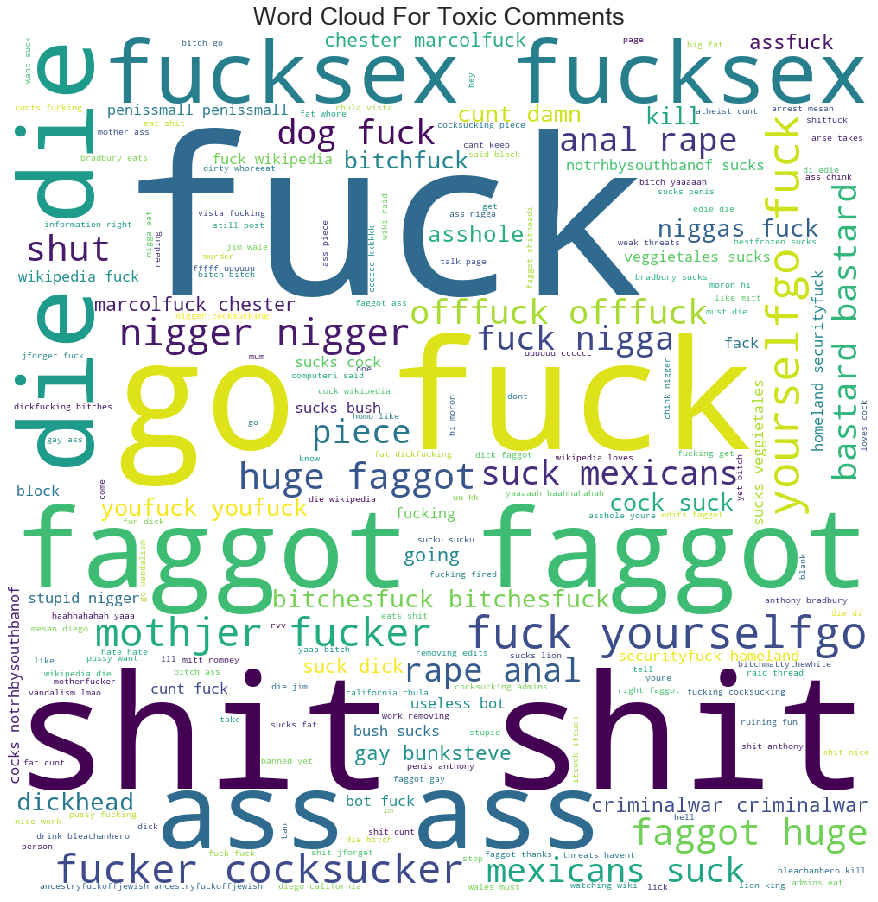

In [62]:
from wordcloud import WordCloud 
   
wordcloud = WordCloud(width = 1000, height = 1000, 
                background_color ='white', 
                min_font_size = 10, stopwords=np.array(stopwords.words('english'))).generate(' '.join(df['clean_comments'][df['severe_toxic']==1].values)) 
  
# plot the WordCloud image                        
plt.figure(figsize = (19, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.title("Word Cloud For Toxic Comments", fontdict={'fontsize': 25})
plt.show() 

In [63]:
getMostCommonNonStopWords(obscene_comments, 20)

[('fuck', 8538),
 ('shit', 3183),
 ('fucking', 3097),
 ('you', 2852),
 ('suck', 2821),
 ('nigger', 2721),
 ('ass', 2517),
 ('go', 2117),
 ('u', 2056),
 ('wikipedia', 1635),
 ('like', 1526),
 ('cunt', 1517),
 ('get', 1399),
 ('bitch', 1392),
 ('fat', 1281),
 ('die', 1169),
 ('know', 1169),
 ('faggot', 1162),
 ('dick', 1143),
 ('im', 1108)]

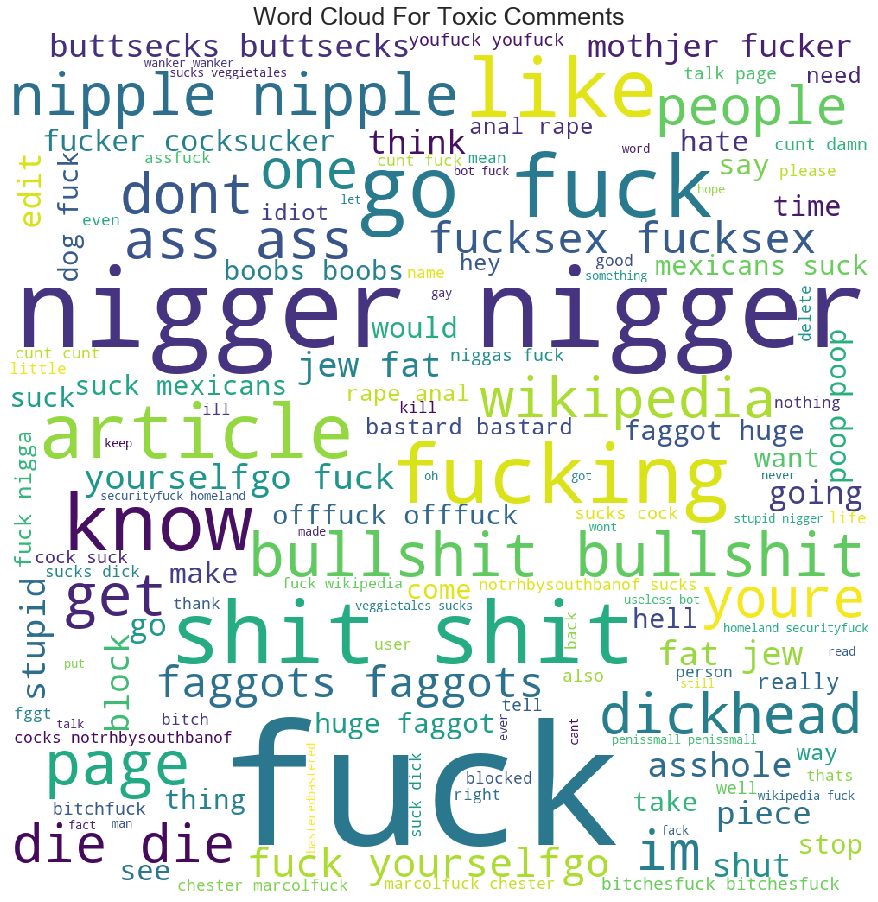

In [64]:
from wordcloud import WordCloud 
   
wordcloud = WordCloud(width = 1000, height = 1000, 
                background_color ='white', 
                min_font_size = 10, stopwords=np.array(stopwords.words('english'))).generate(' '.join(df['clean_comments'][df['obscene']==1].values)) 
  
# plot the WordCloud image                        
plt.figure(figsize = (19, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.title("Word Cloud For Toxic Comments", fontdict={'fontsize': 25})
plt.show() 

In [65]:
getMostCommonNonStopWords(threat_comments, 20)

[('die', 1165),
 ('ass', 769),
 ('you', 617),
 ('kill', 504),
 ('going', 294),
 ('block', 170),
 ('must', 166),
 ('jim', 158),
 ('wales', 157),
 ('supertr0ll', 149),
 ('fucking', 136),
 ('fuck', 134),
 ('im', 132),
 ('ban', 132),
 ('page', 128),
 ('wikipedia', 117),
 ('talk', 112),
 ('murder', 107),
 ('live', 101),
 ('fuckin', 101)]

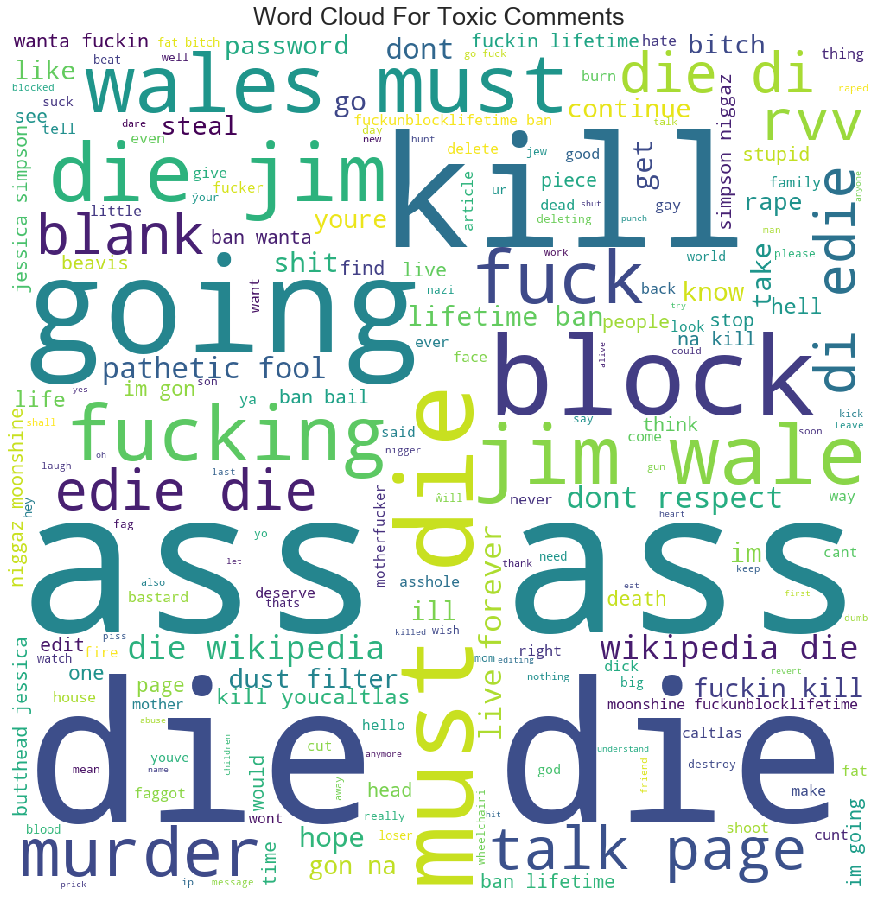

In [66]:
from wordcloud import WordCloud 
   
wordcloud = WordCloud(width = 1000, height = 1000, 
                background_color ='white', 
                min_font_size = 10, stopwords=np.array(stopwords.words('english'))).generate(' '.join(df['clean_comments'][df['threat']==1].values)) 
  
# plot the WordCloud image                        
plt.figure(figsize = (19, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.title("Word Cloud For Toxic Comments", fontdict={'fontsize': 25})
plt.show() 

In [67]:
getMostCommonNonStopWords(insult_comments, 20)

[('fuck', 6620),
 ('nigger', 2774),
 ('fucking', 2710),
 ('suck', 2594),
 ('go', 2209),
 ('you', 2194),
 ('u', 1963),
 ('fat', 1924),
 ('ass', 1886),
 ('faggot', 1803),
 ('shit', 1665),
 ('like', 1546),
 ('moron', 1458),
 ('cunt', 1430),
 ('hi', 1398),
 ('hate', 1383),
 ('bitch', 1335),
 ('jew', 1299),
 ('get', 1295),
 ('wikipedia', 1243)]

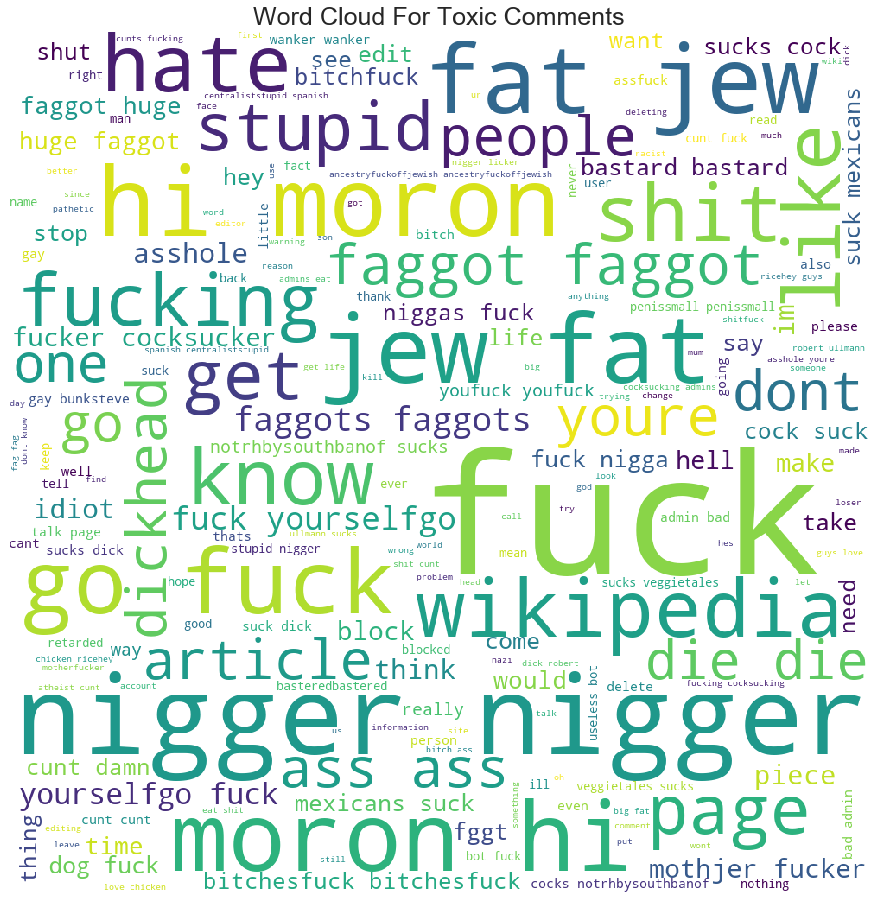

In [68]:
from wordcloud import WordCloud 
   
wordcloud = WordCloud(width = 1000, height = 1000, 
                background_color ='white', 
                min_font_size = 10, stopwords=np.array(stopwords.words('english'))).generate(' '.join(df['clean_comments'][df['insult']==1].values)) 
  
# plot the WordCloud image                        
plt.figure(figsize = (19, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.title("Word Cloud For Toxic Comments", fontdict={'fontsize': 25})
plt.show() 

In [69]:
getMostCommonNonStopWords(identity_hate_comments, 20)

[('nigger', 2963),
 ('fat', 1321),
 ('jew', 1307),
 ('gay', 911),
 ('die', 879),
 ('fuck', 875),
 ('faggot', 685),
 ('fucking', 518),
 ('huge', 429),
 ('suck', 426),
 ('shit', 406),
 ('stupid', 396),
 ('cunt', 392),
 ('like', 382),
 ('ass', 368),
 ('mexicans', 365),
 ('bitch', 345),
 ('niggas', 342),
 ('hate', 289),
 ('go', 284)]

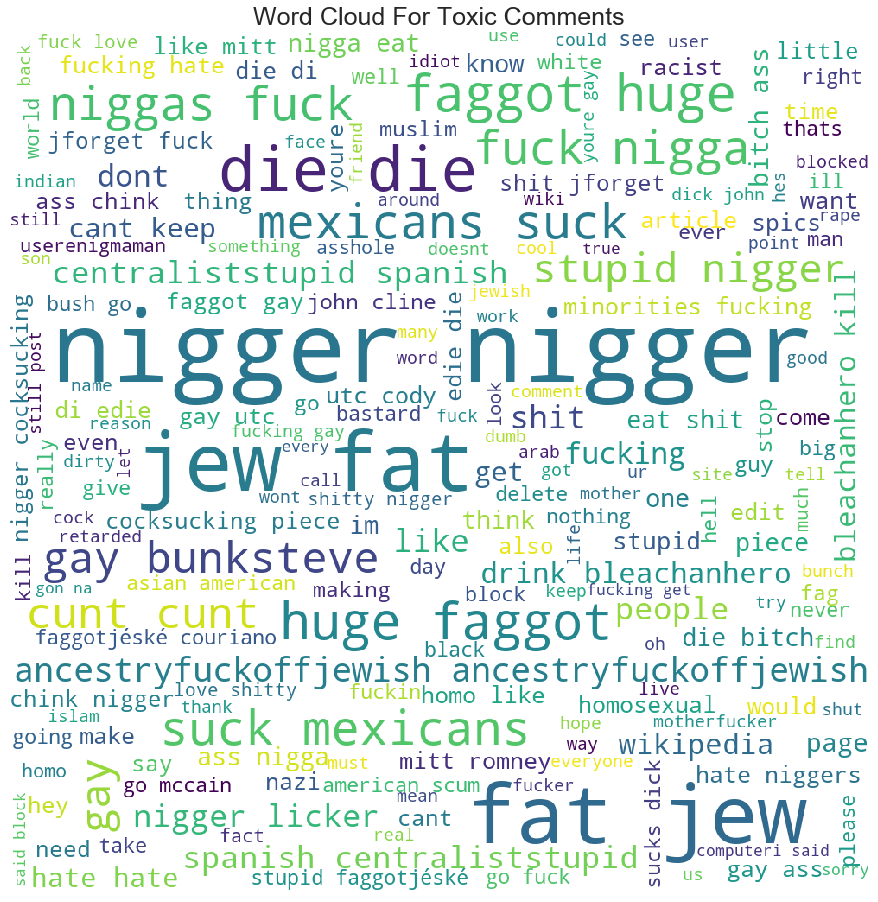

In [70]:
from wordcloud import WordCloud 
   
wordcloud = WordCloud(width = 1000, height = 1000, 
                background_color ='white', 
                min_font_size = 10, stopwords=np.array(stopwords.words('english'))).generate(' '.join(df['clean_comments'][df['identity_hate']==1].values)) 
  
# plot the WordCloud image                        
plt.figure(figsize = (19, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.title("Word Cloud For Toxic Comments", fontdict={'fontsize': 25})
plt.show() 

# Normalizing Comments

In [71]:
# removing html tags
def strip_html_tags(text):
    soup = BeautifulSoup(text,'html.parser')
    stripped_text = soup.get_text()
    return stripped_text

In [72]:
# removing accented characters
def remove_accented_chars(text):
    text = unicodedata.normalize('NFKD',text).encode('ascii','ignore').decode('utf-8','ignore')
    return text

!pip install contractions
from contractions import contractions_dict
# Expand contractions
def expand_contractions(text, contraction_mapping=contractions_dict):
    contractions_pattern = re.compile('({})'.format('|'.join(contraction_mapping.keys())),
                                      flags=re.IGNORECASE|re.DOTALL)
    
    def expand_match(contraction):
        match = contraction.group(0)
        first_char = match[0]
        expanded_contraction = contraction_mapping.get(match)\
                                if contraction_mapping.get(match)\
                                else contraction_mapping.get(match.lower())
        expanded_contraction = first_char + expanded_contraction[1:]
        return expanded_contraction
    
    expanded_text = contractions_pattern.sub(expand_match, text)
    expanded_text = re.sub("'","",expanded_text)
    return expanded_text

In [73]:
nlp = spacy.load('en_core_web_sm', parse=True, tag=True, entity=True)
tokenizer = ToktokTokenizer()
stopword_list = nltk.corpus.stopwords.words('english')

In [74]:
# Lemmatization
def lemmatize_text(text):
    text = nlp(text)
    text = ' '.join([word.lemma_ if word.lemma_ !='-PRON-' else word.text for word in text])
    return text

In [75]:
# Removing special characters
def remove_special_characters(text, remove_digits):
    pattern = r'[^a-zA-Z0-9\s]' if not remove_digits else r'[^a-zA-Z\s]'
    text = re.sub(pattern,'',text)
    return text

In [76]:
# Removing stopwords

def remove_stopwords(text, is_lower_case):
    tokens = tokenizer.tokenize(text)
    tokens = [token.strip() for token in tokens]
    if is_lower_case:
        filtered_tokens = [token for token in tokens if token not in stopword_list]
    else:
        filtered_tokens = [token for token in tokens if token.lower() not in stopword_list]
    filtered_text = ' '.join(filtered_tokens)
    return filtered_text

In [77]:
# Normalized corpus
def normalize_corpus(corpus,html_stripping=True,
                      accented_char_removal=True, text_lower_case=True,
                      text_lemmatization=True, special_char_removal=True,
                      stopword_removal=True):
    
    normalized_corpus = []
    try:
        for doc in corpus:
            # strip HTML
            if html_stripping:
                doc = strip_html_tags(doc)
            # remove accented characters
            if accented_char_removal:
                doc = remove_accented_chars(doc)
            # lowercase the text
            if text_lower_case:
                doc = doc.lower()
            # remove extra newlines
            doc = re.sub(r'[\r|\n\r\n]+','',doc)
            # lemmatize text
            if text_lemmatization:
                doc = lemmatize_text(doc)
            # remove special characters or digits
            if special_char_removal:
                # insert spaces between special character to isolate them
                special_char_pattern = re.compile(r'([{.(-)!}])')
                doc = special_char_pattern.sub(" \\1 ",doc)
                doc = remove_special_characters(doc, True)
            # remove extra whitespace
            doc = re.sub(' +', ' ', doc)
            # remove stopwords
            if stopword_removal:
                doc = remove_stopwords(doc, is_lower_case=text_lower_case)
        
            normalized_corpus.append(doc)
     
        return normalized_corpus 
    except:
        return normalized_corpus

In [78]:
norm_corpus = normalize_corpus(df['clean_comments'],html_stripping=True,
                      accented_char_removal=True, text_lower_case=True,
                      text_lemmatization=True, special_char_removal=True,
                      stopword_removal=True)

In [79]:
norm_corpus[0:5]

['explanation edit make username hardcore metallica fan revert vandalism closure gas vote new york doll fac please remove template talk page since retire',
 'daww match background colour seemingly stick thank talk january utc',
 'hey man really try edit war guy constantly remove relevant information talk edit instead talk page seem care formatting actual info',
 'make real suggestion improvement wonder section statistic later subsection type accident think reference may need tidying exact format ie date format etc later noone else first preference format style reference want please let know appear backlog article review guess may delay reviewer turn list relevant form eg wikipediagoodarticlenominationstransport',
 'sir hero chance remember page']

In [80]:
# Adding normalized data to dataframe
df['Normalized_Comments'] = pd.Series(norm_corpus)

In [81]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment,comment_len,word_count,sentence_count,upper_case,upper_case_perc,punctuation_count,punctuation_perc,clean_comments,tag_count,Normalized_Comments
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0,264,43,3,17,0.064394,10,0.037879,explanation why the edits made under my userna...,0,explanation edit make username hardcore metall...
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0,112,17,4,8,0.071429,12,0.107143,daww he matches this background colour im seem...,0,daww match background colour seemingly stick t...
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0,233,42,3,4,0.017167,6,0.025751,hey man im really not trying to edit war its j...,0,hey man really try edit war guy constantly rem...
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0,622,113,4,11,0.017685,21,0.033762,more cant make any real suggestions on improve...,0,make real suggestion improvement wonder sectio...
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0,67,13,2,2,0.029851,5,0.074627,you sir are my hero any chance you remember wh...,0,sir hero chance remember page


In [82]:
min(df['Normalized_Comments'].apply(len))

0

In [83]:
df = df.replace(r'^(\s?)+$',np.nan,regex=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 19 columns):
id                     159571 non-null object
comment_text           159571 non-null object
toxic                  159571 non-null int64
severe_toxic           159571 non-null int64
obscene                159571 non-null int64
threat                 159571 non-null int64
insult                 159571 non-null int64
identity_hate          159571 non-null int64
bad_comment            159571 non-null int64
comment_len            159571 non-null int64
word_count             159571 non-null int64
sentence_count         159571 non-null int64
upper_case             159571 non-null int64
upper_case_perc        159571 non-null float64
punctuation_count      159571 non-null int64
punctuation_perc       159571 non-null float64
clean_comments         159529 non-null object
tag_count              159571 non-null int64
Normalized_Comments    159454 non-null object
dtypes: float64(2), int64(

In [84]:
df = df[df['Normalized_Comments'].notna()]
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 159454 entries, 0 to 159570
Data columns (total 19 columns):
id                     159454 non-null object
comment_text           159454 non-null object
toxic                  159454 non-null int64
severe_toxic           159454 non-null int64
obscene                159454 non-null int64
threat                 159454 non-null int64
insult                 159454 non-null int64
identity_hate          159454 non-null int64
bad_comment            159454 non-null int64
comment_len            159454 non-null int64
word_count             159454 non-null int64
sentence_count         159454 non-null int64
upper_case             159454 non-null int64
upper_case_perc        159454 non-null float64
punctuation_count      159454 non-null int64
punctuation_perc       159454 non-null float64
clean_comments         159454 non-null object
tag_count              159454 non-null int64
Normalized_Comments    159454 non-null object
dtypes: float64(2), int64(

In [85]:
df.reset_index(inplace= True)
df[-5:]

,index,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment,comment_len,word_count,sentence_count,upper_case,upper_case_perc,punctuation_count,punctuation_perc,clean_comments,tag_count,Normalized_Comments
159449,159566,ffe987279560d7ff,""":::::And for the second time of asking, when ...",0,0,0,0,0,0,0,295,47,2,2,0.006780,18,0.061017,and for the second time of asking when your vi...,0,second time ask view completely contradict cov...
159450,159567,ffea4adeee384e90,You should be ashamed of yourself \n\nThat is ...,0,0,0,0,0,0,0,99,18,2,2,0.020202,4,0.040404,you should be ashamed of yourself that is horr...,0,ashamed horrible thing put talk page
159451,159568,ffee36eab5c267c9,"Spitzer \n\nUmm, theres no actual article for ...",0,0,0,0,0,0,0,81,12,2,4,0.049383,4,0.049383,spitzer umm theres no actual article for prost...,0,spitzer umm actual article prostitution ring c...
159452,159569,fff125370e4aaaf3,And it looks like it was actually you who put ...,0,0,0,0,0,0,0,116,25,1,2,0.017241,1,0.008621,and it looks like it was actually you who put ...,0,look like actually put speedy first version de...
159453,159570,fff46fc426af1f9a,"""\nAnd ... I really don't think you understand...",0,0,0,0,0,0,0,189,36,4,4,0.021164,14,0.074074,and really dont think you understand came here...,0,really think understand come idea bad right aw...


# Building Train and Test Split

In [86]:
from sklearn.model_selection import train_test_split

train_corpus, test_corpus, train_sentence_count, test_sentence_count, train_upper_case_perc, test_upper_case_perc,  train_toxic, test_toxic, train_severe_toxic, test_severe_toxic, train_obscene, test_obscene, train_threat, test_threat,train_insult, test_insult, train_identity_hate, test_identity_hate, train_bad_comment, test_bad_comment= train_test_split(np.array(df['Normalized_Comments']),
                                       np.array(df['sentence_count']), np.array(df['upper_case_perc']), np.array(df['toxic']),np.array(df['severe_toxic']),np.array(df['obscene']),np.array(df['threat']),np.array(df['insult']),np.array(df['identity_hate']),np.array(df['bad_comment']),test_size=0.3, random_state=42)

In [87]:
train_corpus.shape, test_corpus.shape

((111617,), (47837,))

# Building and Evaluating our text classifier (Bad/Not Bad)

In [88]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix

In [89]:
# Build Bag-of-Words features in train articles
cv = CountVectorizer(binary=False, min_df=0.0, max_df=1.0)
cv_train_features = cv.fit_transform(train_corpus)

In [90]:
# Transform test articles into features
cv_test_features = cv.transform(test_corpus)

In [91]:
print("Bag-of-words model:> Train features shape:", cv_train_features.shape,
      "Test features shape:",cv_test_features.shape)

Bag-of-words model:> Train features shape: (111617, 156096) Test features shape: (47837, 156096)


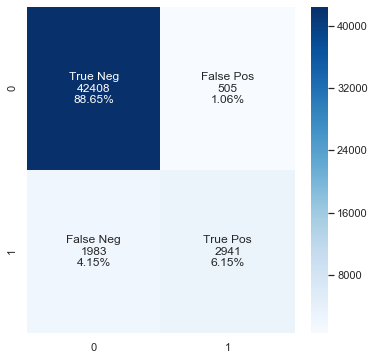



Accuracy=0.948
Precision=0.853
Recall=0.597
F1 Score=0.703


In [92]:
# We will build several classifiers on the train data and test the performance on the test data using the classification models.
# Naive Bayes Classifier
from sklearn.naive_bayes import MultinomialNB

mnb = MultinomialNB(alpha=1)
mnb.fit(cv_train_features, train_bad_comment)
mnb_bow_pred = mnb.predict(cv_test_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,mnb_bow_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

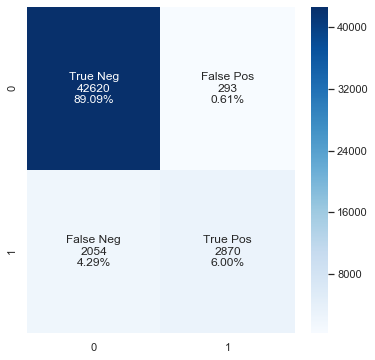



Accuracy=0.951
Precision=0.907
Recall=0.583
F1 Score=0.710


In [93]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(penalty='l2',max_iter=100, C=1, random_state=42)
lr.fit(cv_train_features, train_bad_comment)
lr_bow_pred = lr.predict(cv_test_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,lr_bow_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

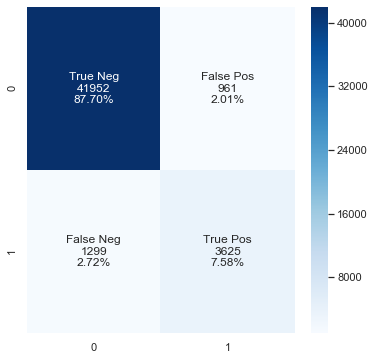



Accuracy=0.953
Precision=0.790
Recall=0.736
F1 Score=0.762


In [94]:
# SVM
from sklearn.svm import LinearSVC

svm = LinearSVC(penalty='l2', C=1, random_state=42)
svm.fit(cv_train_features, train_bad_comment)
svm_bow_pred =svm.predict(cv_test_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,svm_bow_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

# TF-IDF features with Classification Models

In [95]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [96]:
#Build TF-IDF features on train articles
tv = TfidfVectorizer(use_idf=True, min_df=0.0, max_df=1.0)
tv_train_features = tv.fit_transform(train_corpus)

In [97]:
# transform test articles into features
tv_test_features = tv.transform(test_corpus)

In [98]:
print("TF-IDF model:> Train features shape:", tv_train_features.shape,
      "Test features shape:",tv_test_features.shape)

Bag-of-words model:> Train features shape: (111617, 156096) Test features shape: (47837, 156096)


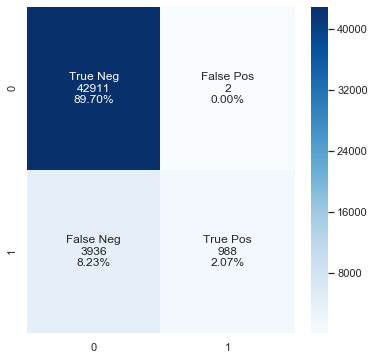



Accuracy=0.918
Precision=0.998
Recall=0.201
F1 Score=0.334


In [99]:
# Naive Bayes
from sklearn.naive_bayes import MultinomialNB

mnb = MultinomialNB(alpha=1)
mnb.fit(tv_train_features, train_bad_comment)
mnb_tv_pred = mnb.predict(tv_test_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,mnb_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

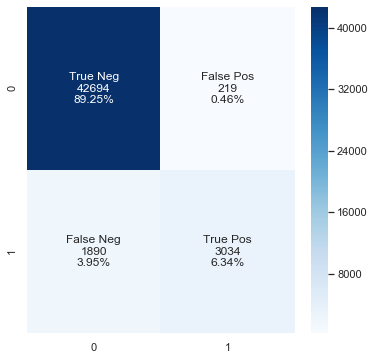



Accuracy=0.956
Precision=0.933
Recall=0.616
F1 Score=0.742


In [100]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(penalty='l2',max_iter=100, C=1, random_state=42)
lr.fit(tv_train_features, train_bad_comment)
lr_tv_pred = lr.predict(tv_test_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,lr_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

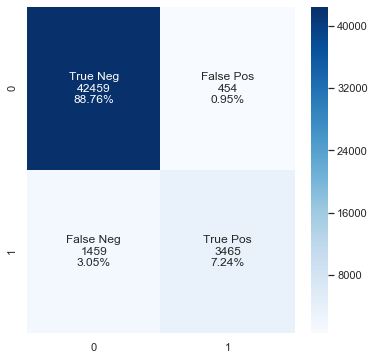



Accuracy=0.960
Precision=0.884
Recall=0.704
F1 Score=0.784


In [101]:
svm = LinearSVC(penalty='l2', C=1, random_state=42)
svm.fit(tv_train_features, train_bad_comment)
svm_tv_pred =svm.predict(tv_test_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,svm_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

<b> In our EDA we found 'sentence_count' and 'upper_case_perc' to be a bit significant. Let's add these features to tf_idf matrix and train the model

In [102]:
import scipy as sp

print(tv_train_features.shape)
print(tv_test_features.shape)

(111617, 156096)
(47837, 156096)


In [103]:
train_sentence_count_reshape = np.reshape(train_sentence_count,(train_sentence_count.size,1))
test_sentence_count_reshape = np.reshape(test_sentence_count,(test_sentence_count.size,1))
train_upper_case_perc_reshape = np.reshape(train_upper_case_perc,(train_upper_case_perc.size,1))
test_upper_case_perc_reshape = np.reshape(test_upper_case_perc,(test_upper_case_perc.size,1))

In [104]:
tv_train_features_eda = sp.sparse.hstack((tv_train_features,train_sentence_count_reshape,train_upper_case_perc_reshape))
tv_test_features_eda  = sp.sparse.hstack((tv_test_features,test_sentence_count_reshape,test_upper_case_perc_reshape))
print(tv_train_features_eda.shape)
print(tv_test_features_eda.shape)

(111617, 156098)
(47837, 156098)


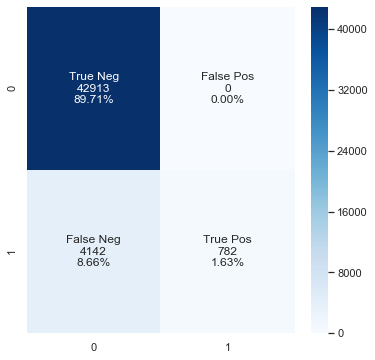



Accuracy=0.913
Precision=1.000
Recall=0.159
F1 Score=0.274


In [105]:
# Naive Bayes

mnb_eda = MultinomialNB(alpha=1)
mnb_eda.fit(tv_train_features_eda, train_bad_comment)
mnb_eda_tv_pred = mnb_eda.predict(tv_test_features_eda)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,mnb_eda_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

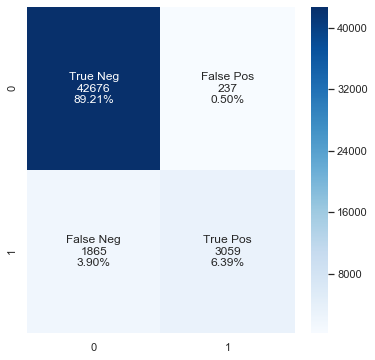



Accuracy=0.956
Precision=0.928
Recall=0.621
F1 Score=0.744


In [106]:
# Logistic Regression
lr_eda = LogisticRegression(penalty='l2',max_iter=100, C=1, random_state=42)
lr_eda.fit(tv_train_features_eda, train_bad_comment)
lr_eda_tv_pred = lr_eda.predict(tv_test_features_eda)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,lr_eda_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

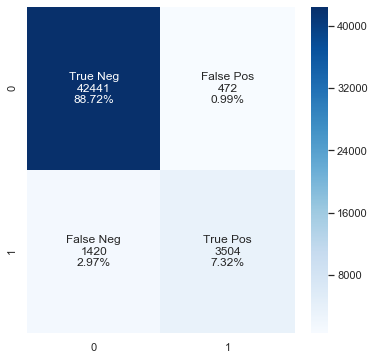



Accuracy=0.960
Precision=0.881
Recall=0.712
F1 Score=0.787


In [107]:
svm_eda = LinearSVC(penalty='l2', C=1, random_state=42)
svm_eda.fit(tv_train_features_eda, train_bad_comment)
svm_eda_tv_pred =svm_eda.predict(tv_test_features_eda)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,svm_eda_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

# Using Class Weights

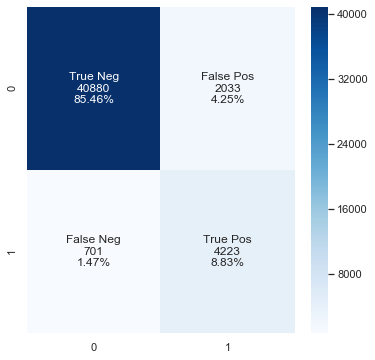



Accuracy=0.943
Precision=0.675
Recall=0.858
F1 Score=0.755


In [182]:
# Logistic Regression
lr_eda = LogisticRegression(penalty='l2',max_iter=100, C=1, random_state=42, class_weight= 'balanced')
lr_eda.fit(tv_train_features_eda, train_bad_comment)
lr_eda_tv_pred = lr_eda.predict(tv_test_features_eda)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,lr_eda_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

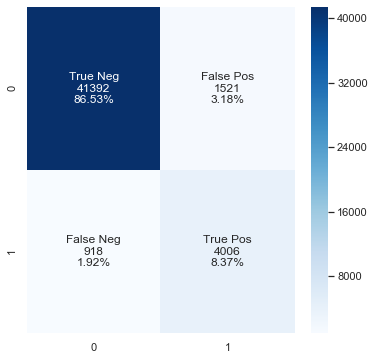



Accuracy=0.949
Precision=0.725
Recall=0.814
F1 Score=0.767


In [184]:
svm_eda = LinearSVC(penalty='l2', C=1, random_state=42,class_weight= 'balanced')
svm_eda.fit(tv_train_features_eda, train_bad_comment)
svm_eda_tv_pred =svm_eda.predict(tv_test_features_eda)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,svm_eda_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

<b> One common observation across all methods is SVM is performing very well (good recall) compared to other models

# POS Tagging the comments to see if some particular type of POS is relevant in classifying the comments

In [108]:
import spacy
nlp = spacy.load('en_core_web_sm')

In [109]:
# Normalized corpus
def normalize_corpus_pos(corpus,html_stripping=True,
                      accented_char_removal=True, text_lower_case=True, special_char_removal=True):
    
    normalized_corpus_pos = []
    try:
        for doc in corpus:
            # strip HTML
            if html_stripping:
                doc = strip_html_tags(doc)
            # remove accented characters
            if accented_char_removal:
                doc = remove_accented_chars(doc)
            # lowercase the text
            if text_lower_case:
                doc = doc.lower()
            # remove extra newlines
            doc = re.sub(r'[\r|\n\r\n]+','',doc)
            # remove special characters or digits
            if special_char_removal:
                # insert spaces between special character to isolate them
                special_char_pattern = re.compile(r'([{.(-)!}])')
                doc = special_char_pattern.sub(" \\1 ",doc)
                doc = remove_special_characters(doc, True)
            # remove extra whitespace
            doc = re.sub(' +', ' ', doc)
        
            normalized_corpus_pos.append(doc)
     
        return normalized_corpus_pos 
    except:
        return normalized_corpus_pos

In [110]:
norm_corpus_pos = normalize_corpus_pos(df['comment_text'],html_stripping=True,
                      accented_char_removal=True, text_lower_case=True, special_char_removal=True)


In [111]:
norm_corpus_pos = pd.Series(norm_corpus_pos)
len(norm_corpus_pos)

159454

In [112]:
norm_corpus_pos[159330:159337]

159330    hisometimes you are wright sometimes i am rihg...
159331                                  yeah i no it sucks 
159332                             i think he is a gay fag 
159333                seems likely from their descriptions 
159334    filecti measurements jpg listed for deletion a...
159335    i am really sorry about your relatives but any...
159336    neutrality can we get a professional thats not...
dtype: object

In [113]:
df.head()

,index,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment,comment_len,word_count,sentence_count,upper_case,upper_case_perc,punctuation_count,punctuation_perc,clean_comments,tag_count,Normalized_Comments
0,0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0,264,43,3,17,0.064394,10,0.037879,explanation why the edits made under my userna...,0,explanation edit make username hardcore metall...
1,1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0,112,17,4,8,0.071429,12,0.107143,daww he matches this background colour im seem...,0,daww match background colour seemingly stick t...
2,2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0,233,42,3,4,0.017167,6,0.025751,hey man im really not trying to edit war its j...,0,hey man really try edit war guy constantly rem...
3,3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0,622,113,4,11,0.017685,21,0.033762,more cant make any real suggestions on improve...,0,make real suggestion improvement wonder sectio...
4,4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0,67,13,2,2,0.029851,5,0.074627,you sir are my hero any chance you remember wh...,0,sir hero chance remember page


In [185]:

    df['POS_Normalized_Comments'] = norm_corpus_pos

## Considering only Adjectives from the comments

In [186]:
adjs = []
verbs = []
nouns = []
for comment in df['POS_Normalized_Comments']:
    doc = nlp(comment)
    adj_tokens = [tok.lemma_.lower().strip() for tok in doc if tok.pos_ == 'ADJ']
    adjs.append(adj_tokens)
    
    verb_tokens = [tok.lemma_.lower().strip() for tok in doc if tok.pos_ == 'VERB']
    verbs.append(verb_tokens)
    
    noun_tokens = [tok.lemma_.lower().strip() for tok in doc if tok.pos_ == 'NOUN']
    nouns.append(noun_tokens)
    
    

In [187]:
# Creating copies of the lists just to be safe

adjs_1 = adjs.copy()
verbs_1 = verbs.copy()
nouns_1 = nouns.copy()

In [188]:
adjs_joined = [" ".join(x for x in comment) for comment in adjs]
verbs_joined = [" ".join(x for x in comment) for comment in verbs]
nouns_joined = [" ".join(x for x in comment) for comment in nouns]

In [189]:
adjs_joined[:5]

['username', '', 'relevant more actual', 'real exact same relevant', '']

In [190]:
df['adjs'] = pd.Series(adjs_joined)
df['verbs'] = pd.Series(verbs_joined)
df['nouns'] = pd.Series(nouns_joined)
df['adjs_verbs_nouns'] = df['adjs']+df['verbs']+df['nouns']

In [191]:
df.head()

,index,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment,...,punctuation_count,punctuation_perc,clean_comments,tag_count,Normalized_Comments,POS_Normalized_Comments,adjs,verbs,nouns,adjs_verbs_nouns
0,0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0,...,10,0.037879,explanation why the edits made under my userna...,0,explanation edit make username hardcore metall...,explanationwhy the edits made under my usernam...,username,make revert closure vote remove be retire,edit vandalism gas doll template talk page,usernamemake revert closure vote remove be ret...
1,1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0,...,12,0.107143,daww he matches this background colour im seem...,0,daww match background colour seemingly stick t...,daww he matches this background colour im seem...,,match be stick talk,background colour thank,match be stick talkbackground colour thank
2,2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0,...,6,0.025751,hey man im really not trying to edit war its j...,0,hey man really try edit war guy constantly rem...,hey man im really not trying to edit war its j...,relevant more actual,be try edit remove talk seem care,war guy information edit talk page formatting ...,relevant more actualbe try edit remove talk se...
3,3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0,...,21,0.033762,more cant make any real suggestions on improve...,0,make real suggestion improvement wonder sectio...,morei cant make any real suggestions on improv...,real exact same relevant,can make wonder should think may need can form...,suggestion improvement section statistic subse...,real exact same relevantcan make wonder should...
4,4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0,...,5,0.074627,you sir are my hero any chance you remember wh...,0,sir hero chance remember page,you sir are my hero any chance you remember wh...,,remember s,hero chance page,remember shero chance page


In [192]:
train_adjs_corpus, test_adjs_corpus, train_verbs_corpus, test_verbs_corpus, train_nouns_corpus, test_nouns_corpus, train_avn_corpus, test_avn_corpus,  train_bad_comment, test_bad_comment= train_test_split(np.array(df['adjs']),
                                       np.array(df['verbs']), np.array(df['nouns']),np.array(df['adjs_verbs_nouns']),np.array(df['bad_comment']),test_size=0.3, random_state=42)

In [193]:
train_adjs_corpus.shape, test_adjs_corpus.shape

((111617,), (47837,))

## Modelling With Adjectives

In [194]:
#Build TF-IDF features on train articles
tv = TfidfVectorizer(use_idf=True, min_df=0.0, max_df=1.0)
tv_train_adjs_features = tv.fit_transform(train_adjs_corpus)
# transform test articles into features
tv_test_adjs_features = tv.transform(test_adjs_corpus)
print("TF-IDF model:> Train features shape:", tv_train_adjs_features.shape,
      "Test features shape:",tv_test_adjs_features.shape)

TF-IDF model:> Train features shape: (111617, 26259) Test features shape: (47837, 26259)


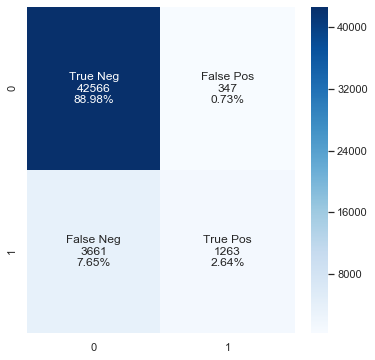



Accuracy=0.916
Precision=0.784
Recall=0.256
F1 Score=0.387


In [195]:
svm_adjs = LinearSVC(penalty='l2', C=1, random_state=42)
svm_adjs.fit(tv_train_adjs_features, train_bad_comment)
svm_adjs_tv_pred =svm_adjs.predict(tv_test_adjs_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,svm_adjs_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

## Modelling With Verbs

In [196]:
#Build TF-IDF features on train articles
tv = TfidfVectorizer(use_idf=True, min_df=0.0, max_df=1.0)
tv_train_verbs_features = tv.fit_transform(train_verbs_corpus)
# transform test articles into features
tv_test_verbs_features = tv.transform(test_verbs_corpus)
print("TF-IDF model:> Train features shape:", tv_train_verbs_features.shape,
      "Test features shape:",tv_test_verbs_features.shape)

TF-IDF model:> Train features shape: (111617, 28337) Test features shape: (47837, 28337)


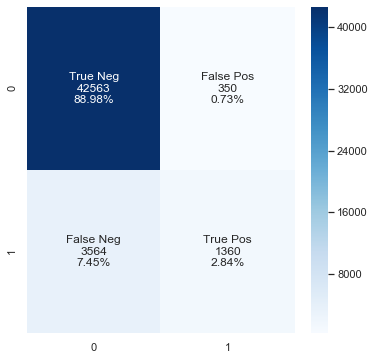



Accuracy=0.918
Precision=0.795
Recall=0.276
F1 Score=0.410


In [197]:
svm_verbs = LinearSVC(penalty='l2', C=1, random_state=42)
svm_verbs.fit(tv_train_verbs_features, train_bad_comment)
svm_verbs_tv_pred =svm_verbs.predict(tv_test_verbs_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,svm_verbs_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

## Modelling With Nouns

In [198]:
#Build TF-IDF features on train articles
tv = TfidfVectorizer(use_idf=True, min_df=0.0, max_df=1.0)
tv_train_nouns_features = tv.fit_transform(train_nouns_corpus)
# transform test articles into features
tv_test_nouns_features = tv.transform(test_nouns_corpus)
print("TF-IDF model:> Train features shape:", tv_train_nouns_features.shape,
      "Test features shape:",tv_test_nouns_features.shape)

TF-IDF model:> Train features shape: (111617, 75969) Test features shape: (47837, 75969)


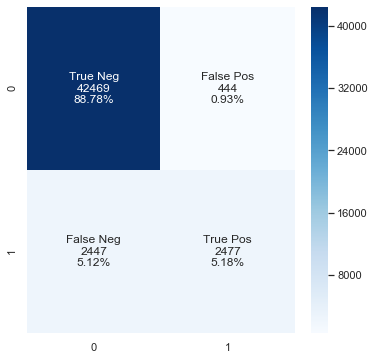



Accuracy=0.940
Precision=0.848
Recall=0.503
F1 Score=0.631


In [199]:
svm_nouns = LinearSVC(penalty='l2', C=1, random_state=42)
svm_nouns.fit(tv_train_nouns_features, train_bad_comment)
svm_nouns_tv_pred =svm_nouns.predict(tv_test_nouns_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,svm_nouns_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

## Modelling With Adjectives, Verbs and Nouns

In [200]:
#Build TF-IDF features on train articles
tv = TfidfVectorizer(use_idf=True, min_df=0.0, max_df=1.0)
tv_train_avn_features = tv.fit_transform(train_avn_corpus)
# transform test articles into features
tv_test_avn_features = tv.transform(test_avn_corpus)
print("TF-IDF model:> Train features shape:", tv_train_avn_features.shape,
      "Test features shape:",tv_test_avn_features.shape)

TF-IDF model:> Train features shape: (111617, 225701) Test features shape: (47837, 225701)


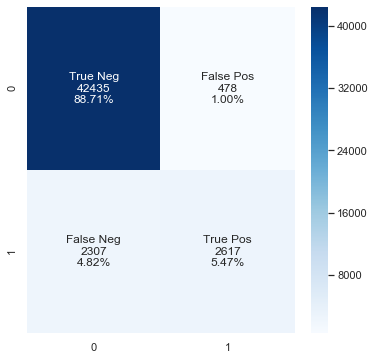



Accuracy=0.942
Precision=0.846
Recall=0.531
F1 Score=0.653


In [201]:
svm_avn = LinearSVC(penalty='l2', C=1, random_state=42)
svm_avn.fit(tv_train_avn_features, train_bad_comment)
svm_avn_tv_pred =svm_avn.predict(tv_test_avn_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,svm_avn_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

## Using upsampling to deal with imbalanace

In [161]:
train_data = pd.concat([pd.DataFrame(train_corpus,columns = ["Normalized_Comments"]),pd.DataFrame(train_bad_comment,columns = ["bad_comment"])],axis = 1)
type(train_data)  
train_data.head()

,Normalized_Comments,bad_comment
0,though lol,0
1,question commitment scheme work seem handy com...,0
2,already ask pretty much tell stick head bucket...,1
3,thank delicious carbuncle admission however en...,0
4,ok citation still need history section dal lak...,0


In [175]:
len(train_data[train_data["bad_comment"] == 0]),len(train_data[train_data["bad_comment"] == 1])

(100323, 11294)

In [166]:
from sklearn.utils import resample

# Separate majority and minority classes
df_majority = train_data[train_data.bad_comment==0]
df_minority = train_data[train_data.bad_comment==1]
 
# Upsample minority class
df_minority_upsampled = resample(df_minority, 
                                 replace=True,     # sample with replacement
                                 n_samples=100323,    # to match majority class
                                 random_state=123) # reproducible results
 
# Combine majority class with upsampled minority class
df_upsampled = pd.concat([df_majority, df_minority_upsampled])
 
# Display new class counts
df_upsampled.bad_comment.value_counts()

1    100323
0    100323
Name: bad_comment, dtype: int64

In [169]:
#Build TF-IDF features on train articles
up_tv = TfidfVectorizer(use_idf=True, min_df=0.0, max_df=1.0)
up_tv_train_features = up_tv.fit_transform(df_upsampled["Normalized_Comments"])

# transform test articles into features
up_tv_test_features = up_tv.transform(test_corpus)

In [172]:
len(test_corpus),len(test_bad_comment)

(47837, 47837)

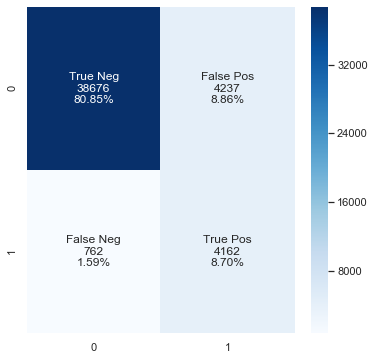



Accuracy=0.895
Precision=0.496
Recall=0.845
F1 Score=0.625


In [171]:
# Naive Bayes
from sklearn.naive_bayes import MultinomialNB

mnb = MultinomialNB(alpha=1)
mnb.fit(up_tv_train_features,df_upsampled["bad_comment"])
up_mnb_tv_pred = mnb.predict(up_tv_test_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,up_mnb_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

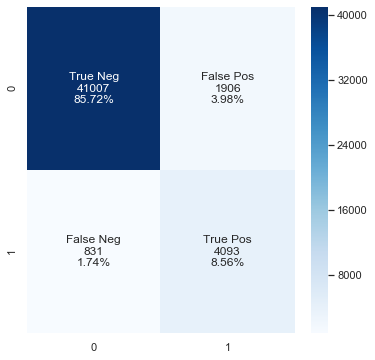



Accuracy=0.943
Precision=0.682
Recall=0.831
F1 Score=0.749


In [173]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(penalty='l2',max_iter=100, C=1, random_state=42)
lr.fit(up_tv_train_features, df_upsampled["bad_comment"])
up_lr_tv_pred = lr.predict(up_tv_test_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,up_lr_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

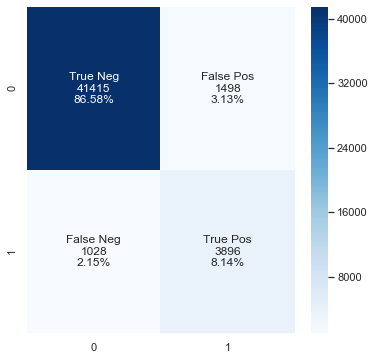



Accuracy=0.947
Precision=0.722
Recall=0.791
F1 Score=0.755


In [174]:
svm = LinearSVC(penalty='l2', C=1, random_state=42)
svm.fit(up_tv_train_features, df_upsampled["bad_comment"])
up_svm_tv_pred =svm.predict(up_tv_test_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,up_svm_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

## Using downsampling to deal with imbalanace

In [176]:
# Separate majority and minority classes
df_majority = train_data[train_data.bad_comment==0]
df_minority = train_data[train_data.bad_comment==1]
 
# Downsample majority class
df_majority_downsampled = resample(df_majority, 
                                 replace=False,    # sample without replacement
                                 n_samples=11294,     # to match minority class
                                 random_state=1234) # reproducible results
 
# Combine minority class with downsampled majority class
df_downsampled = pd.concat([df_majority_downsampled, df_minority])
 
# Display new class counts
df_downsampled.bad_comment.value_counts()

1    11294
0    11294
Name: bad_comment, dtype: int64

In [177]:
#Build TF-IDF features on train articles
ds_tv = TfidfVectorizer(use_idf=True, min_df=0.0, max_df=1.0)
ds_tv_train_features = ds_tv.fit_transform(df_downsampled["Normalized_Comments"])

# transform test articles into features
ds_tv_test_features = ds_tv.transform(test_corpus)

<b> Aren't we reducing the train dataset by huge number

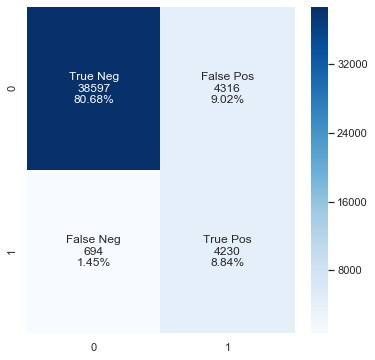



Accuracy=0.895
Precision=0.495
Recall=0.859
F1 Score=0.628


In [179]:
# Naive Bayes
from sklearn.naive_bayes import MultinomialNB

mnb = MultinomialNB(alpha=1)
mnb.fit(ds_tv_train_features, df_downsampled["bad_comment"])
ds_mnb_tv_pred = mnb.predict(ds_tv_test_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,ds_mnb_tv_pred)

grods_names = ['True Neg','False Pos','False Neg','True Pos']

grods_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

grods_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(grods_names,grods_counts,grods_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

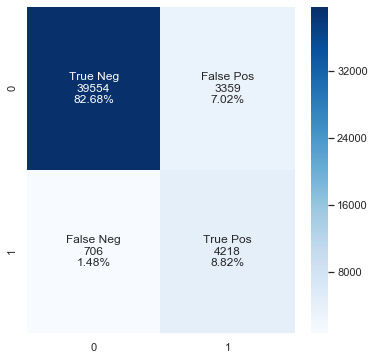



Accuracy=0.915
Precision=0.557
Recall=0.857
F1 Score=0.675


In [180]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(penalty='l2',max_iter=100, C=1, random_state=42)
lr.fit(ds_tv_train_features, df_downsampled["bad_comment"])
ds_lr_tv_pred = lr.predict(ds_tv_test_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,ds_lr_tv_pred)

grods_names = ['True Neg','False Pos','False Neg','True Pos']

grods_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

grods_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(grods_names,grods_counts,grods_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

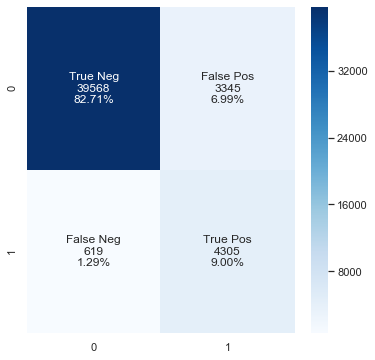



Accuracy=0.917
Precision=0.563
Recall=0.874
F1 Score=0.685


In [181]:
svm = LinearSVC(penalty='l2', C=1, random_state=42)
svm.fit(ds_tv_train_features,df_downsampled["bad_comment"])
ds_svm_tv_pred =svm.predict(ds_tv_test_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,ds_svm_tv_pred)

grods_names = ['True Neg','False Pos','False Neg','True Pos']

grods_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

grods_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(grods_names,grods_counts,grods_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

# Word2Vec

In [ ]:
from gensim.models import Word2Vec

In [ ]:
Bigger_list = []
for i  in train_corpus:
    li = list(i.split(" "))
    Bigger_list.append(li)
Model = Word2Vec(Bigger_list,min_count=15,size=5000,sg = 0) # What is sg?

In [ ]:
# Function to average all word vectors in a paragraph
def featureVecMethod(words, model, num_features):
    # Pre-initialising empty numpy array for speed
    featureVec = np.zeros(num_features,dtype="float32")
    nwords = 0
    
    #Converting Index2Word which is a list to a set for better speed in the execution.
    index2word_set = set(model.wv.index2word)
    
    for word in  words:
        if word in index2word_set:
            nwords = nwords + 1
            featureVec = np.add(featureVec,model[word])
    
    # Dividing the result by number of words to get average
    featureVec = np.divide(featureVec, nwords)
    return featureVec

In [ ]:
# Function for calculating the average feature vector
def getAvgFeatureVecs(reviews, model, num_features):
    counter = 0
    reviewFeatureVecs = np.zeros((len(reviews),num_features),dtype="float32")
    for review in reviews:
        # Printing a status message every 1000th review
        if counter%1000 == 0:
            print("Review %d of %d"%(counter,len(reviews)))
            
        reviewFeatureVecs[counter] = featureVecMethod(review, model, num_features)
        counter = counter+1
        
    return reviewFeatureVecs

In [ ]:
# Calculating average feature vector for training set
clean_train_comments = []
for comment in train_corpus:
    clean_train_comments.append(comment.split())
    
trainDataVecs = getAvgFeatureVecs(clean_train_comments, Model, 5000)

In [ ]:
# Calculating average feature vactors for test set     
clean_test_comments = []
for review in test_corpus:
    clean_test_comments.append(review.split())
    
testDataVecs = getAvgFeatureVecs(clean_test_comments, Model, 5000)

In [ ]:
lr_wv = LogisticRegression(random_state = 0)
lr_wv.fit(trainDataVecs,train_bad_comment)
lr_wv_pred = lr_wv.predict(testDataVecs)

In [ ]:
np.any(np.isnan(trainDataVecs))

In [ ]:
np.any(np.isnan(testDataVecs))

In [ ]:
np.any(np.isnan(clean_train_comments))

In [ ]:
type(clean_train_comments)

In [ ]:
import math
math.isnan(clean_train_comments)

In [ ]:
type(clean_train_comments[0])

In [ ]:
for x in clean_train_comments:
    for y in x:
        if y != y:
            print(True)
       
   

In [ ]:
pd.isnull